# Notebook 04: What is shear-wave splitting?

**Goal (about 3 hours, best split over two sessions):** build the splitting measurement yourself on a synthetic signal where the answer is known, then see what changes at a real station: the geometry of the ray (the shear-wave window and the ray frame), the source polarization of local earthquakes, and one real split at STAR. Sections 1 to 6 (the synthetic) take about 1.25 hours, sections 7 to 9 (STAR) about 45 minutes, and the exercises about an hour. Section 10 is optional reading (15 minutes). The whole notebook runs in about two minutes.

By the end you should be able to explain, for STAR:

- what phi, dt and percent anisotropy measure, and why the direction of phi alone cannot tell stress from structure there;
- how a grid search finds phi and dt, and how noise, nulls and cycle skips fool it;
- why the pipeline rejects rays that arrive more than 45 degrees from vertical, and what "phi from Q" means;
- how the synthetic maps onto STAR: its dominant periods, its 0.02 s steps of dt, and the pipeline's SNR.

Sections 1 to 6 use no splitting library, only numpy. The physics reference is Crampin & Peacock (2008); the method is Silver & Chan (1991). This lesson builds on notebook 03, which defined phi, dt, the dominant period, the cycle skip, the SNR and the filter bank; they are not re-defined here. Words in **bold** are defined where they first appear, and section 11 collects them in a glossary.

In [1]:
# --- setup: make the repo importable and keep figures inline ---
import sys
from pathlib import Path
REPO = Path.cwd().parent if (Path.cwd() / "../rainier_sws").exists() else Path.cwd()
sys.path.insert(0, str(REPO))
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.ticker as mticker
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from rainier_sws import paths, data, measure, quality, stats, reference
from rainier_sws import sws_functions as swsf

def plain_ticks(ax, ticks, axis="x"):
    """Label a logarithmic axis with plain numbers (as in notebook 03)."""
    a = ax.xaxis if axis == "x" else ax.yaxis
    (ax.set_xticks if axis == "x" else ax.set_yticks)(ticks)
    a.set_major_formatter(mticker.FormatStrFormatter("%g")); a.set_minor_formatter(mticker.NullFormatter())

print("repo:", REPO)

repo: /Users/mhemmett/Seismology/rainier-sws-tutorials


## 1. The physical picture

Shallow rock is full of small cracks and larger fractures. Where they line up, the rock is **anisotropic**: its wave speed depends on direction. An S wave shaking the ground *parallel* to the cracks shears the rock without disturbing them and travels at the normal speed. An S wave shaking *across* the cracks makes their faces slide against each other; the cracks make the rock softer to that kind of shearing, so that wave travels slightly slower. The direction in which a wave shakes the ground is its **polarization**.

A general S wave is a vector; decompose it into those two polarizations and the two parts travel at different speeds. By the time they reach the station the slow one lags the fast one by dt, and the fast one is polarized along phi, measured clockwise from north (notebook 03, section 8). phi is an axis, so phi and phi + 180 are the same.

For an ECE student: the ground between earthquake and station is a two-input two-output linear system whose eigenmodes are "shake along phi" and "shake across phi", with impulse responses delta(t) and delta(t - dt). We want to identify phi and dt from the output alone.

### Stress or structure?

Two kinds of alignment compete, and telling them apart is this project's research question (README).

- **Stress.** Rock under stress is squeezed harder in one direction than in the others. The **maximum horizontal compressive stress** is the horizontal direction in which the rock is squeezed hardest. Thin cracks across that direction are pressed shut and cracks along it stay open, so the open cracks, and the fast direction, line up with it. Regionally it points about NE (the clockwise rotation of the Pacific Northwest). Under the summit the weight of the edifice adds a large vertical stress, but splitting of near-vertical rays senses the horizontal part.
- **Structure.** Faults, old dikes and layered lava flows are planes of weakness that can hold aligned fractures whatever the present stress. Then the fast direction follows their strike. The 2009 swarm outlined a nearly vertical structure striking about NE (Shelly, Moran and Thelen, 2013).

The figure draws the two cases in map view and then the directions that matter at Rainier, from `rainier_sws.reference` and from STAR's measurements on the corrected components (README, *Known facts*).

STAR: mean fast direction 33.7 deg (68% bootstrap 32.8 to 34.7), N = 194
regional compression 45 deg, 2009 structure 45 deg (both approximate)


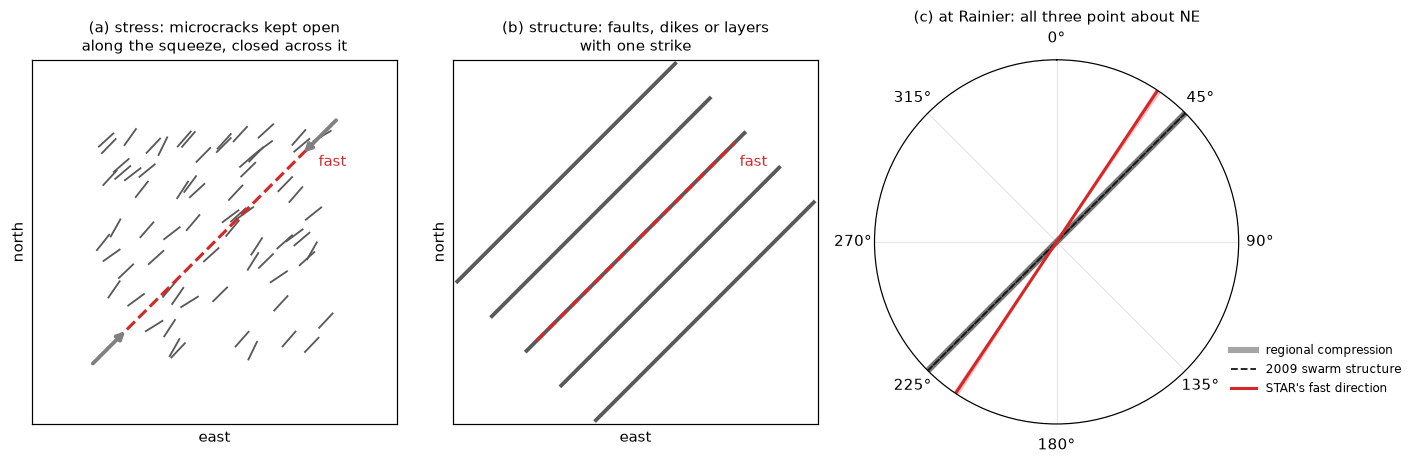

In [2]:
res_o = pd.read_csv(paths.station_results_csv("STAR", oriented=True))   # STAR re-run on true Z/N/E (README)
good = quality.post_filtered(res_o)                                      # the measurements that pass every cut
phi_star, lo_star, hi_star, _ = stats.bootstrap_axial_mean(good.phi)     # mean axis and its 68% interval

def draw_axis(ax, az, r=1.0, **kw):
    """A line through the origin along azimuth az (deg clockwise from north), in map coordinates."""
    a = np.deg2rad(az)
    ax.plot([-r * np.sin(a), r * np.sin(a)], [-r * np.cos(a), r * np.cos(a)], **kw)

rng_art = np.random.default_rng(0)
fig = plt.figure(figsize=(13, 4.4))
ax1, ax2 = fig.add_subplot(1, 3, 1), fig.add_subplot(1, 3, 2)
# (a) microcracks held open by the stress: short, many, aligned with the squeeze
for x, y, az in zip(rng_art.uniform(-0.8, 0.8, 70), rng_art.uniform(-0.8, 0.8, 70),
                    rng_art.normal(reference.REGIONAL_COMPRESSION_AZ, 8, 70)):
    a = np.deg2rad(az)
    ax1.plot([x - 0.07 * np.sin(a), x + 0.07 * np.sin(a)], [y - 0.07 * np.cos(a), y + 0.07 * np.cos(a)], color="0.35", lw=1.2)
a = np.deg2rad(reference.REGIONAL_COMPRESSION_AZ)
for s in (-1, 1):   # the squeeze: arrows pointing inward along the compression direction
    ax1.annotate("", xy=(0.88 * s * np.sin(a), 0.88 * s * np.cos(a)), xytext=(1.25 * s * np.sin(a), 1.25 * s * np.cos(a)),
                 arrowprops=dict(arrowstyle="-|>", color="0.5", lw=2.5))
ax1.set_title("(a) stress: microcracks kept open\nalong the squeeze, closed across it", fontsize=10)
# (b) structure: a few long faults or dikes with one strike
for off in np.linspace(-0.7, 0.7, 5):
    b = np.deg2rad(reference.STRUCTURE_2009_STRIKE)
    cx, cy = off * np.cos(b), -off * np.sin(b)           # offset perpendicular to the strike
    ax2.plot([cx - 1.1 * np.sin(b), cx + 1.1 * np.sin(b)], [cy - 1.1 * np.cos(b), cy + 1.1 * np.cos(b)], color="0.35", lw=2.5)
ax2.set_title("(b) structure: faults, dikes or layers\nwith one strike", fontsize=10)
for ax, az in [(ax1, reference.REGIONAL_COMPRESSION_AZ), (ax2, reference.STRUCTURE_2009_STRIKE)]:
    draw_axis(ax, az, r=1.0, color="tab:red", lw=2, ls="--")
    ax.text(0.98 * np.sin(np.deg2rad(az)) + 0.05, 0.98 * np.cos(np.deg2rad(az)) - 0.15, "fast", color="tab:red")
    ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect="equal", xticks=[], yticks=[], xlabel="east", ylabel="north")
# (c) the directions at Rainier
ax3 = fig.add_subplot(1, 3, 3, projection="polar")
ax3.set_theta_zero_location("N"); ax3.set_theta_direction(-1)
for az, style, label in [(reference.REGIONAL_COMPRESSION_AZ, dict(color="0.3", lw=4, alpha=0.5), "regional compression"),
                         (reference.STRUCTURE_2009_STRIKE, dict(color="0.1", lw=1.2, ls="--"), "2009 swarm structure")]:
    ax3.plot(np.deg2rad([az, az + 180]), [1, 1], **style, label=label)
    ax3.plot(np.deg2rad([az + 180, az + 360]), [1, 1], **style)
for base in (0, 180):
    ax3.fill_between(np.deg2rad(np.linspace(phi_star + lo_star, phi_star + hi_star, 10) + base), 0, 1, color="tab:red", alpha=0.3, lw=0)
    ax3.plot(np.deg2rad([phi_star + base] * 2), [0, 1], color="tab:red", lw=2, label="STAR's fast direction" if base == 0 else None)
ax3.set(rticks=[], ylim=(0, 1)); ax3.set_title("(c) at Rainier: all three point about NE", fontsize=10)
ax3.legend(loc="upper left", bbox_to_anchor=(0.95, 0.25), fontsize=8, frameon=False)
plt.tight_layout()
print(f"STAR: mean fast direction {phi_star:.1f} deg (68% bootstrap {phi_star + lo_star:.1f} to {phi_star + hi_star:.1f}), N = {len(good)}")
print(f"regional compression {reference.REGIONAL_COMPRESSION_AZ:.0f} deg, 2009 structure {reference.STRUCTURE_2009_STRIKE:.0f} deg (both approximate)")

At Rainier the two hypotheses point the same way: the regional compression and the 2009 structure are both about 45 degrees (both values approximate), and STAR's mean fast direction is 33.7 degrees, with a 68 percent bootstrap interval of 32.8 to 34.7 (N = 194). That is about 11 degrees from both references, so **the direction of phi alone cannot separate stress from structure at STAR**. What can: differences between stations (a structure is local, the regional stress is not), changes with time (stress-aligned cracks can open and close during a swarm; an old dike cannot move), and how much anisotropy there is.

### How strong: percent anisotropy

If the fast and slow S speeds differ by a small fraction k, a wave that travels for a time t picks up a delay dt of about k times t. The delay grows with the length of the anisotropic path; dividing it out gives a property of the rock, the **percent anisotropy**: 100 x dt / (S travel time), the percentage by which the slow wave is slower than the fast one, averaged along the path. More open, aligned cracks give more anisotropy, so it is the project's measure of crack density, and a change in it during a swarm would say the cracks changed.

The **travel time** in the results file (`travel_time_s`) is the S travel time computed by ray tracing through the pipeline's velocity model, not one read off the seismogram. Exercise 5 asks whether that choice matters. The project reports percent anisotropy as the mean with a 68 percent bootstrap interval, with the median alongside.

percent anisotropy at STAR, N = 194: mean 2.93 (68% bootstrap 2.85 to 3.01), median 3.25 (3.23 to 3.27)
travel times 1.36 to 2.16 s, median 1.81 s; delays: {0.02: 43, 0.04: 12, 0.06: 116, 0.08: 23}


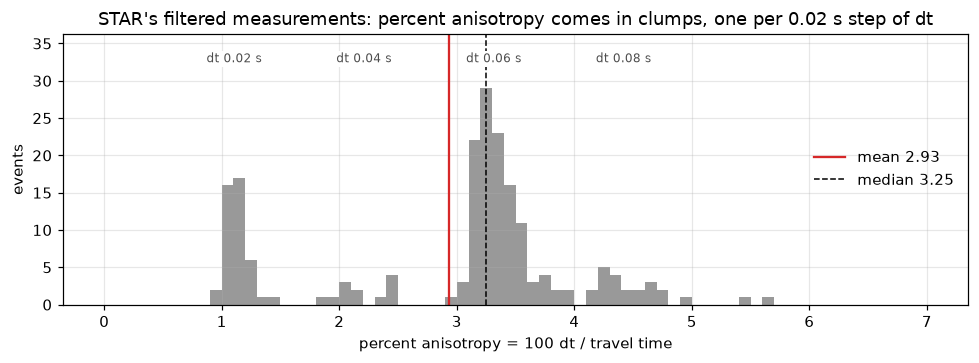

In [3]:
tt = good.travel_time_s                                   # S travel time from the pipeline's ray tracing (s)
pct = 100 * good.dt / tt
assert np.allclose(pct, good.pct_anisotropy)              # the results file's column is exactly this
m_pct, m_lo, m_hi, _ = stats.bootstrap(pct.to_numpy(), np.mean)
md_pct, md_lo, md_hi, _ = stats.bootstrap(pct.to_numpy(), np.median)
print(f"percent anisotropy at STAR, N = {len(pct)}: mean {m_pct:.2f} (68% bootstrap {m_lo:.2f} to {m_hi:.2f}), "
      f"median {md_pct:.2f} ({md_lo:.2f} to {md_hi:.2f})")
print(f"travel times {tt.min():.2f} to {tt.max():.2f} s, median {tt.median():.2f} s; "
      f"delays: {good.dt.round(2).value_counts().sort_index().to_dict()}")

fig, ax = plt.subplots(figsize=(9, 3.4))
counts_pct, _, _ = ax.hist(pct, bins=np.arange(0, 7.01, 0.1), color="0.6")
ax.axvline(m_pct, color="tab:red", lw=1.5, label=f"mean {m_pct:.2f}")
ax.axvline(md_pct, color="k", lw=1, ls="--", label=f"median {md_pct:.2f}")
ax.set_ylim(0, counts_pct.max() * 1.25)
for d_ in sorted(good.dt.round(2).unique()):
    ax.text(100 * d_ / tt.median(), counts_pct.max() * 1.12, f"dt {d_:.2f} s", ha="center", fontsize=8, color="0.3",
            bbox=dict(fc="w", ec="none", pad=1))
ax.set(xlabel="percent anisotropy = 100 dt / travel time", ylabel="events",
       title="STAR's filtered measurements: percent anisotropy comes in clumps, one per 0.02 s step of dt")
ax.legend(frameon=False, loc="center right")
plt.tight_layout()

STAR's percent anisotropy is 2.93 on average (68 percent bootstrap interval 2.85 to 3.01; median 3.25, 3.23 to 3.27; N = 194). The histogram is not smooth: it comes in four clumps, one for each value of dt (0.02, 0.04, 0.06 and 0.08 s, with 43, 12, 116 and 23 events), spread a little by the travel times of 1.36 to 2.16 s. That is the grid SWSPy measures dt on (notebook 03, section 8; section 8 below). The mean and the median differ by 0.3 because of it: the median sits inside the large 0.06 s clump, while the 43 events at 0.02 s pull the mean down. Which of the two summarizes STAR better depends on whether those 0.02 s events are a different population (exercise 2 suggests they mostly come from one filter band).

## 2. Make a split wave

Start with a clean S pulse polarized in some direction, then apply the split: rotate into the fast/slow frame, delay the slow component, rotate back to north/east. The direction the S wave shakes before it is split is its **source polarization**: for a local earthquake it is set by how the fault slipped (section 6).

The pulse is a Ricker wavelet with a peak frequency of 8 Hz, so its period is 1/8 = 0.125 s. That is close to the dominant period of STAR's events filtered at 5-10 Hz (0.115 s); the more common 1-5 Hz events are slower (0.19 s; section 8). The synthetic pretends the wave comes straight up from below, so that north and east are the whole story; section 7 deals with real, slanted rays.

The right panel is a **particle motion** plot: north against east, the path the ground traces in map view.

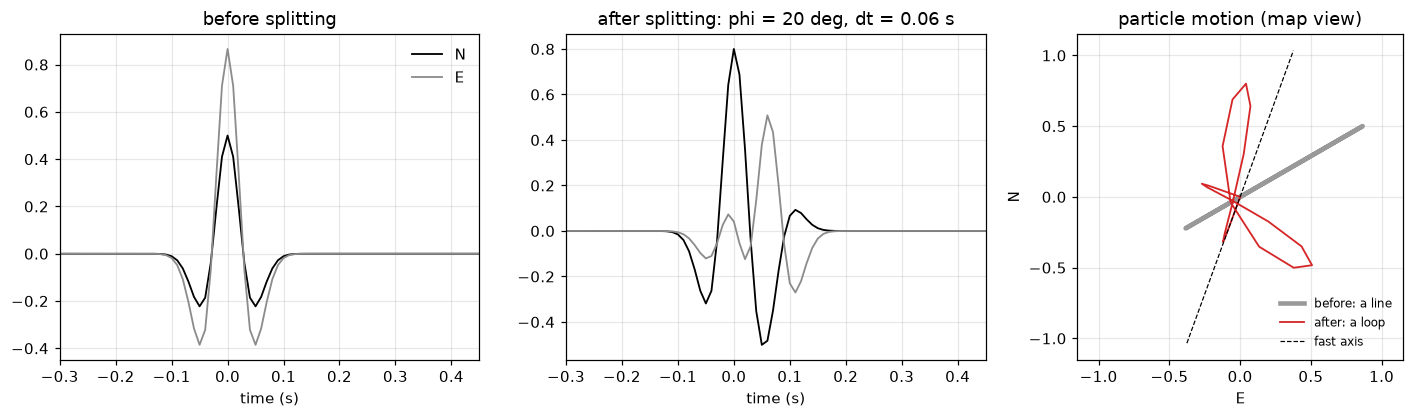

In [4]:
fs = 100.0                                   # samples per second, as at STAR
t = np.arange(-0.5, 1.5, 1 / fs)             # time (s); the pulse is centred on t = 0

def ricker(t, f0=8.0):
    """A Ricker wavelet with peak frequency f0 (Hz): a clean, one-swing S pulse."""
    a = (np.pi * f0 * t) ** 2
    return (1 - 2 * a) * np.exp(-a)

def split(n, e, phi, dt, fs=fs):
    """Apply splitting with fast axis phi (deg clockwise from N) and delay dt (s) to north/east traces."""
    # fast/slow frame: fast = component along phi, slow = perpendicular
    th = np.deg2rad(phi)
    fast = n * np.cos(th) + e * np.sin(th)
    slow = -n * np.sin(th) + e * np.cos(th)
    slow = np.roll(slow, int(round(dt * fs)))          # delay the slow wave
    n2 = fast * np.cos(th) - slow * np.sin(th)
    e2 = fast * np.sin(th) + slow * np.cos(th)
    return n2, e2

src_pol, PHI_TRUE, DT_TRUE = 60.0, 20.0, 0.06
pulse = ricker(t)
n0, e0 = pulse * np.cos(np.deg2rad(src_pol)), pulse * np.sin(np.deg2rad(src_pol))   # unsplit
n1, e1 = split(n0, e0, PHI_TRUE, DT_TRUE)                                             # split

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.25, 1.25, 1]})
for ax, (n_, e_), title in zip(axes[:2], [(n0, e0), (n1, e1)],
                               ["before splitting", f"after splitting: phi = {PHI_TRUE:g} deg, dt = {DT_TRUE} s"]):
    ax.plot(t, n_, color="k", lw=1.2, label="N"); ax.plot(t, e_, color="0.55", lw=1.2, label="E")
    ax.set(xlim=(-0.3, 0.45), xlabel="time (s)", title=title)
axes[0].legend(frameon=False, loc="upper right")
axes[2].plot(e0, n0, color="0.6", lw=3, label="before: a line")
axes[2].plot(e1, n1, color="tab:red", lw=1.2, label="after: a loop")
a = np.deg2rad(PHI_TRUE)
axes[2].plot([-1.1 * np.sin(a), 1.1 * np.sin(a)], [-1.1 * np.cos(a), 1.1 * np.cos(a)], "k--", lw=0.8, label="fast axis")
axes[2].set(aspect="equal", xlim=(-1.15, 1.15), ylim=(-1.15, 1.15), xlabel="E", ylabel="N", title="particle motion (map view)")
axes[2].legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()

The particle motion is the key diagnostic in all of shear-wave splitting. An unsplit S wave has **linear** particle motion: the ground moves back and forth along one line, here the source polarization at 60 degrees. After splitting, the two delayed components no longer rise and fall together, and the motion opens into a loop. For a pulse with several swings the loop has several lobes rather than the neat ellipse a pure sine wave would give. The whole measurement is: find the (phi, dt) that turns the loop back into a line.

## 3. Undo the split: the grid search

For a trial (phi, dt): rotate into the trial fast/slow frame, advance the slow component by dt, and ask how linear the motion now is. Linearity is measured by the 2x2 **covariance matrix** of the two components inside an **analysis window** (the stretch of trace that contains the S wave): its larger eigenvalue, **lambda1**, is the energy along the main direction of motion, and its smaller one, **lambda2**, the energy across it. A line has lambda2 = 0. So we try every (phi, dt) on a grid and keep the one with the smallest lambda2: Silver & Chan's **eigenvalue method**. The window here, from -0.2 to 0.6 s, holds the pulse and its delayed copy.

In [5]:
def unsplit(n, e, phi, dt, fs=fs):
    """Rotate into a trial fast/slow frame and advance the slow component by dt."""
    th = np.deg2rad(phi)
    fast = n * np.cos(th) + e * np.sin(th)
    slow = -n * np.sin(th) + e * np.cos(th)
    slow = np.roll(slow, -int(round(dt * fs)))
    return fast, slow

def lambda2(n, e, phi, dt, win):
    f, s = unsplit(n, e, phi, dt)
    cov = np.cov(np.vstack([f[win], s[win]]))
    return np.linalg.eigvalsh(cov)[0]          # smaller eigenvalue

phis = np.arange(0, 180, 1.0)                                    # trial fast directions, 1 degree apart
dts = np.arange(0, measure.SwsParams().max_t_shift_s, 0.01)       # trial delays up to the pipeline's largest (0.2 s)
win = (t > -0.2) & (t < 0.6)                                      # analysis window: the pulse and its delayed copy
grid = np.array([[lambda2(n1, e1, p, d, win) for d in dts] for p in phis])
ip, idt = np.unravel_index(np.argmin(grid), grid.shape)
print(f"recovered phi = {phis[ip]:.0f} deg, dt = {dts[idt]:.2f} s   (truth: {PHI_TRUE}, {DT_TRUE})")

recovered phi = 20 deg, dt = 0.06 s   (truth: 20.0, 0.06)


The double loop computes 180 x 20 = 3600 small covariance matrices with Python loops, which is slow if we want to repeat it thousands of times (section 5). The same numbers come out of array arithmetic: rotate for all phi at once, stack the shifted slow components for all dt, and use the closed form for the eigenvalues of a 2x2 symmetric matrix. `misfit` does that and is checked against the loop. Plotted over the whole grid, the misfit is the **misfit surface**.

the fast grid equals the loop: True


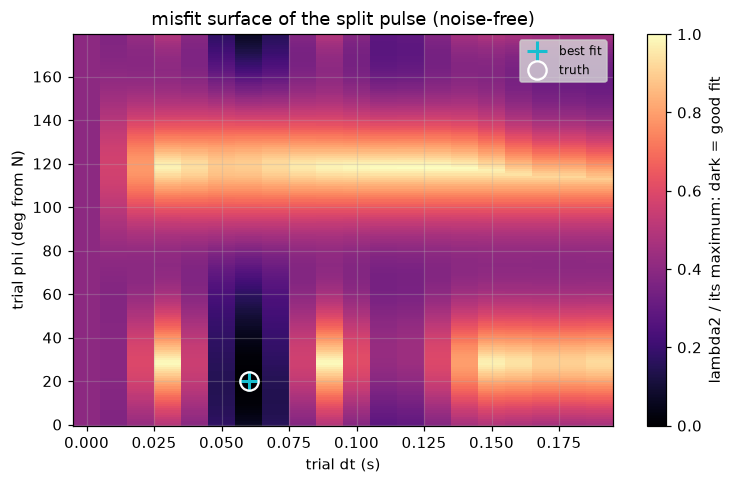

In [6]:
def misfit(n, e, win=win, phis=phis, dts=dts, ratio=False):
    """The whole lambda2 grid at once: the same numbers as the loop above, about a hundred times faster.
    For a 2x2 covariance [[a, c], [c, b]] the eigenvalues are (a+b)/2 -+ sqrt(((a-b)/2)^2 + c^2).
    ratio=True returns lambda2 / lambda1 instead, which is what SWSPy minimizes."""
    th = np.deg2rad(phis)[:, None]
    fast = n * np.cos(th) + e * np.sin(th)                                   # (phi, time)
    slow = -n * np.sin(th) + e * np.cos(th)
    F = fast[:, None, win]                                                   # (phi, 1, window)
    S = np.stack([np.roll(slow, -int(round(d * fs)), axis=1)[:, win] for d in dts], axis=1)   # (phi, dt, window)
    F, S = F - F.mean(-1, keepdims=True), S - S.mean(-1, keepdims=True)
    k = win.sum() - 1
    a, b, c = (F * F).sum(-1) / k, (S * S).sum(-1) / k, (F * S).sum(-1) / k
    mid, rad = (a + b) / 2, np.sqrt(((a - b) / 2) ** 2 + c ** 2)
    return (mid - rad) / (mid + rad) if ratio else mid - rad

def best(g, dts=dts, phis=phis):
    """(phi, dt) at the minimum of a misfit grid."""
    i, j = np.unravel_index(np.argmin(g), g.shape)
    return phis[i], dts[j]

def show_grid(ax, g, title, truth=(PHI_TRUE, DT_TRUE), dts=dts, phis=phis):
    """Draw a misfit surface relative to its maximum: dark = good fit (as in SWSPy's own plots, notebook 05)."""
    im = ax.pcolormesh(dts, phis, g / g.max(), shading="nearest", cmap="magma", vmin=0, vmax=1)
    p, d = best(g, dts, phis)
    ax.plot(d, p, "+", color="tab:cyan", ms=13, mew=2, label="best fit")
    if truth is not None:
        ax.plot(truth[1], truth[0], "o", mfc="none", mec="w", ms=12, mew=1.5, label="truth")
    ax.set(xlabel="trial dt (s)", ylabel="trial phi (deg from N)", title=title)
    return im

print("the fast grid equals the loop:", np.allclose(misfit(n1, e1), grid))
fig, ax = plt.subplots(figsize=(7, 4.5))
im = show_grid(ax, grid, "misfit surface of the split pulse (noise-free)")
fig.colorbar(im, ax=ax, label="lambda2 / its maximum: dark = good fit")
ax.legend(loc="upper right", fontsize=8, facecolor="0.85")
plt.tight_layout()

The surface has one sharp, dark minimum at the truth (phi 20 degrees, dt 0.06 s). Around it:

- along the true dt, a dark column at most trial phi: for most trial axes, advancing the slow component by the right amount still leaves less energy across the motion than a wrong delay does;
- bright spots about 0.03 s either side of the true dt, where the trial delay lines a peak of one component up with a trough of the other;
- swapping fast and slow (phi + 90 = 110 degrees, the bright band) would need a negative dt, which the grid does not contain.

Repeated minima along the dt axis are where cycle skips come from (notebook 03, section 7; exercise 2), and a surface with no single minimum is a **null** (section 6).

The synthetic is simpler than SWSPy in four ways, worth knowing before you compare the two: SWSPy minimizes lambda2 / lambda1 rather than lambda2 (Wüstefeld et al., 2010); it tries dt in steps of 0.02 s at 100 Hz rather than 0.01 s (`measure.dt_step`; section 8); it works in the ray frame rather than in north and east (section 7); and it repeats the search in 49 analysis windows and clusters the answers (section 10).

## 4. Now add noise, and the error bars appear

Real seismograms are noisy. Add white noise and look at the misfit surface again. Here the noise level is set by the synthetic's own SNR, the peak amplitude of the pulse over the standard deviation of the noise. That is **not** the pipeline's SNR (notebook 03, section 5); section 5 converts one into the other.

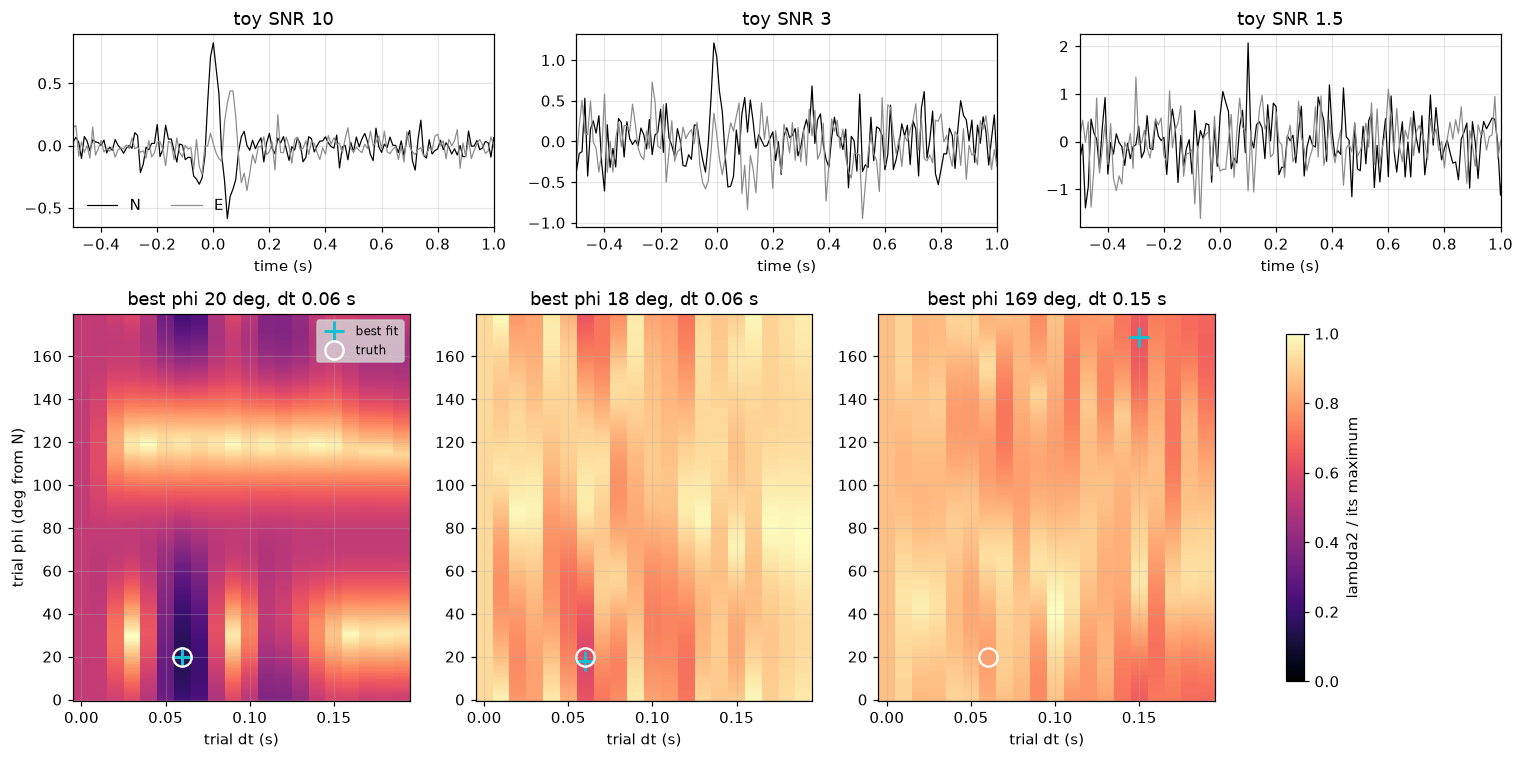

In [7]:
rng = np.random.default_rng(1)
def add_noise(n, e, snr):
    """Add white noise to N and E. snr is the toy's own definition: peak amplitude / noise standard deviation."""
    amp = np.max(np.hypot(n, e)) / snr
    return n + rng.normal(0, amp, n.size), e + rng.normal(0, amp, e.size)

fig, axes = plt.subplots(2, 3, figsize=(14, 7), gridspec_kw={"height_ratios": [1, 2]})
for k, snr in enumerate((10, 3, 1.5)):
    nn, ee = add_noise(n1, e1, snr)
    axes[0, k].plot(t, nn, color="k", lw=0.8, label="N"); axes[0, k].plot(t, ee, color="0.55", lw=0.8, label="E")
    axes[0, k].set(xlim=(-0.5, 1.0), title=f"toy SNR {snr}", xlabel="time (s)")
    g = misfit(nn, ee)
    p, d = best(g)
    im = show_grid(axes[1, k], g, f"best phi {p:.0f} deg, dt {d:.2f} s")
    if k:
        axes[1, k].set_ylabel("")
axes[0, 0].legend(frameon=False, ncol=2, loc="lower left")
axes[1, 0].legend(loc="upper right", fontsize=8, facecolor="0.85")
plt.tight_layout()
cb = fig.colorbar(im, ax=axes[1], label="lambda2 / its maximum", shrink=0.9)

At SNR 10 (top left) the pulse stands out clearly and the surface still has one dark minimum at the truth. At SNR 3 the pulse is still visible by eye and the grid still finds phi 18 and dt 0.06 s, but the surface is pale everywhere: the minimum is only a little lower than its surroundings, so many (phi, dt) fit almost as well. At SNR 1.5 the pulse is hard to see, the surface has no clear valley, and the answer (phi 169, dt 0.15 s) is wrong in both.

The set of (phi, dt) that fit almost as well as the best is the uncertainty: *the width of the valley is the error bar*. Silver & Chan make that precise with an **F-test**, a statistical test of whether the misfit at a trial point is significantly worse than at the minimum, given how many independent samples the window holds; the region that passes is reported as the **formal errors** `phi_error` and `dt_error`. SWSPy reports the half-widths of that region at 99.7 percent confidence on its grid, so `dt_error` cannot go below 0.01 s (README, *Known facts*). Exercise 4 tests how well a valley width predicts the real error.

## 5. A first calibration experiment

Repeat the noisy recovery many times at each noise level and look at the spread of recovered phi and dt. This is the simplest possible answer to "how good is the measurement as a function of SNR?", and the template for the real calibration in notebook 07. Two things make it comparable with the pipeline:

- **200 trials per level.** A median of 25 noisy trials moves by several degrees from one set of trials to the next; with 200 it is pinned to a degree or two, and the cell reports a 68 percent bootstrap interval to show it.
- **The pipeline's SNR.** For every trial, `pipeline_snr` computes the SNR the way the pipeline does (mean |S| in the 0.2 s after the S pick over mean |noise| in the window just before it, averaged over N and E; `sws_functions._s_wave_snr_prefiltered`), with the S pick at the start of the pulse and STAR's median S-P time. The toy has no P wave, so its "P coda" window holds only noise. For 25 trials per level it also runs the pipeline's filter bank first, which is what the pipeline's gate actually sees.

A trial counts as right if phi is within 20 degrees of the truth (`TOL_DEG`): a choice for this lesson, the same width as the null screen of section 9.

In [8]:
from obspy import Stream, Trace, UTCDateTime
cat = data.load_station_catalog("STAR")
SP = (cat.s_time - cat.p_time).dt.total_seconds().median()      # STAR's median S-P time (s)
T0, S_PICK = UTCDateTime(2025, 7, 9), -0.10                       # the toy's t = 0, and where its pulse starts (2% of the peak)
TOL_DEG = 20.0                                                    # "close enough" in this lesson: phi within 20 deg of the truth

def pipeline_snr(n, e, bank=False):
    """The pipeline's SNR (notebook 03, section 5) of a toy trace pair: S against the window just before it,
    which at STAR is P coda and in the toy is only noise. bank=True runs the filter bank first, as the pipeline does."""
    st = Stream([Trace(np.asarray(x, float), header={"channel": ch, "sampling_rate": fs, "starttime": T0 + t[0]})
                 for x, ch in [(np.zeros_like(n), "HHZ"), (n, "HHN"), (e, "HHE")]])
    s_time = T0 + S_PICK
    if bank:
        return swsf.try_filters(st, s_time - SP, s_time)[2]
    return swsf._s_wave_snr_prefiltered(st, s_time - SP, s_time)[0]

rng = np.random.default_rng(2)
rows = []
for snr in [1.5, 2, 3, 5, 10, 20]:
    for k in range(200):
        nn, ee = add_noise(n1, e1, snr)
        p, d = best(misfit(nn, ee))
        rows.append({"toy_snr": snr, "phi": p, "dt": d, "pipeline_snr": pipeline_snr(nn, ee),
                     "after_bank": pipeline_snr(nn, ee, bank=True) if k < 25 else np.nan})   # the bank is slower: 25 trials
res = pd.DataFrame(rows)
res["phi_err"] = stats.axial_diff(res.phi, PHI_TRUE)
res["dt_err"] = (res.dt - DT_TRUE).abs()

def median_68(x):
    """Median and its 68% bootstrap interval."""
    m, lo, hi, _ = stats.bootstrap(x.to_numpy(), np.median, n_boot=500)
    return pd.Series({"median": m, "lo": lo, "hi": hi})

summary = res.groupby("toy_snr").agg(N=("phi", "size"), pipeline_snr=("pipeline_snr", "median"),
                                      after_bank=("after_bank", "median"),
                                      within_tol=("phi_err", lambda x: (x <= TOL_DEG).mean()),
                                      dt_exact=("dt_err", lambda x: (x < 0.005).mean()))
summary = summary.join(res.groupby("toy_snr").phi_err.apply(median_68).unstack().add_prefix("phi_err_"))
summary.round(2)

,N,pipeline_snr,after_bank,within_tol,dt_exact,phi_err_median,phi_err_lo,phi_err_hi
toy_snr,,,,,,,,
1.5,200,1.14,1.84,0.30,0.11,38.0,34.0,40.0
2.0,200,1.23,2.27,0.31,0.08,36.5,34.0,38.5
3.0,200,1.47,2.55,0.48,0.25,22.0,20.0,24.0
5.0,200,2.04,3.69,0.72,0.50,12.0,12.0,13.5
10.0,200,3.57,6.71,0.99,0.96,4.0,4.0,5.0
20.0,200,6.89,11.64,1.00,1.00,2.0,2.0,2.0


The table answers the conversion question first. The toy's SNR and the pipeline's are different statistics: toy SNR 5 is a pipeline SNR of 2.04 on the same trace, and toy SNR 10 is 3.57. Without any signal the pipeline's SNR would be about 1 (two windows of the same noise), which is why it bottoms out at 1.14 for the noisiest level. The filter bank raises it further, to 3.69 and 6.71, because white noise has energy at every frequency and the bank keeps only the band where the pulse is. Now the errors, against the pipeline's SNR of the trace being measured:

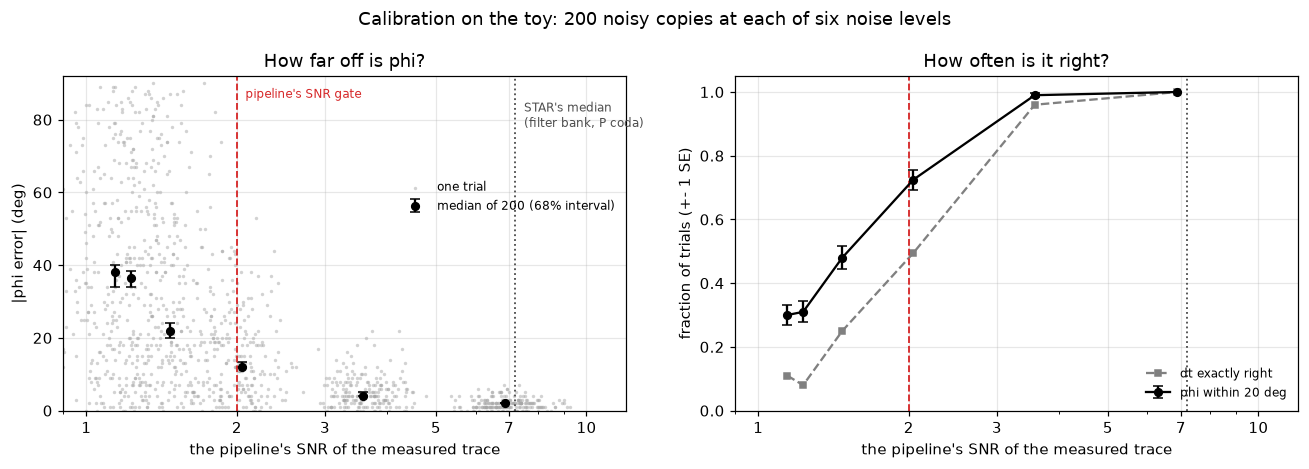

In [9]:
star_snr = res_o.snr_horizontal.median()       # STAR's events: after the filter bank, against P coda (notebook 03)
gate = quality.PreGates().snr_min
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].scatter(res.pipeline_snr, res.phi_err, s=5, color="0.65", alpha=0.5, lw=0, label="one trial")
axes[0].errorbar(summary.pipeline_snr, summary.phi_err_median,
                 yerr=[summary.phi_err_median - summary.phi_err_lo, summary.phi_err_hi - summary.phi_err_median],
                 fmt="o", color="k", ms=5, capsize=3, label="median of 200 (68% interval)")
axes[0].set(ylabel="|phi error| (deg)", ylim=(0, 92), title="How far off is phi?")
se = np.sqrt(summary.within_tol * (1 - summary.within_tol) / summary.N)
axes[1].errorbar(summary.pipeline_snr, summary.within_tol, yerr=se, fmt="o-", color="k", ms=5, capsize=3,
                 label=f"phi within {TOL_DEG:.0f} deg")
axes[1].plot(summary.pipeline_snr, summary.dt_exact, "s--", color="0.5", ms=4, label="dt exactly right")
axes[1].set(ylabel="fraction of trials (+- 1 SE)", ylim=(0, 1.05), title="How often is it right?")
for ax in axes:
    ax.axvline(gate, color="tab:red", ls="--", lw=1.2)
    ax.axvline(star_snr, color="0.3", ls=":", lw=1.2)
    ax.set(xscale="log", xlim=(0.9, 12), xlabel="the pipeline's SNR of the measured trace")
    plain_ticks(ax, [1, 2, 3, 5, 7, 10])
axes[0].text(gate * 1.04, 86, "pipeline's SNR gate", color="tab:red", fontsize=8)
axes[0].text(star_snr * 1.04, 78, "STAR's median\n(filter bank, P coda)", color="0.3", fontsize=8)
axes[0].legend(frameon=False, loc="upper right", fontsize=8, bbox_to_anchor=(1.0, 0.72))
axes[1].legend(frameon=False, loc="lower right", fontsize=8)
fig.suptitle("Calibration on the toy: 200 noisy copies at each of six noise levels")
plt.tight_layout()

- **At the pipeline's SNR gate** (`quality.PreGates().snr_min` = 2; toy SNR 5): the median phi error is 12 degrees (68 percent interval 12 to 13.5), 72 percent of trials are within 20 degrees and dt is exactly right in half of them. So in the toy, a measurement just at the gate is usually close but wrong in more than a quarter of cases.
- **Below the gate** (pipeline SNR 1.1 to 1.5): the median error is 22 to 38 degrees and fewer than half the trials are within 20.
- **Above it**: at a pipeline SNR of 3.6 the median error is 4 degrees and 99 percent are within 20; at 6.9 it is 2 degrees, with dt right every time.

STAR's events have a median pipeline SNR of 7.2 (dotted line), well to the right of the region where the toy struggles. Two cautions keep that from being a guarantee. That 7.2 is measured after the filter bank and against P coda, not white noise (notebook 03, exercise 2); and a real S wave is not a clean single pulse in white noise. Exercise 4 looks at what else the pipeline checks; notebook 07, exercise 4, does this calibration properly, with real STAR waveforms pushed through the whole pipeline.

## 6. The null measurement

What if the source polarization happens to be *along* the fast axis (or exactly across it)? Then all the energy is on one of the two axes, there is nothing on the other to delay, and the wave arrives unsplit. A naive grid search still returns a number.

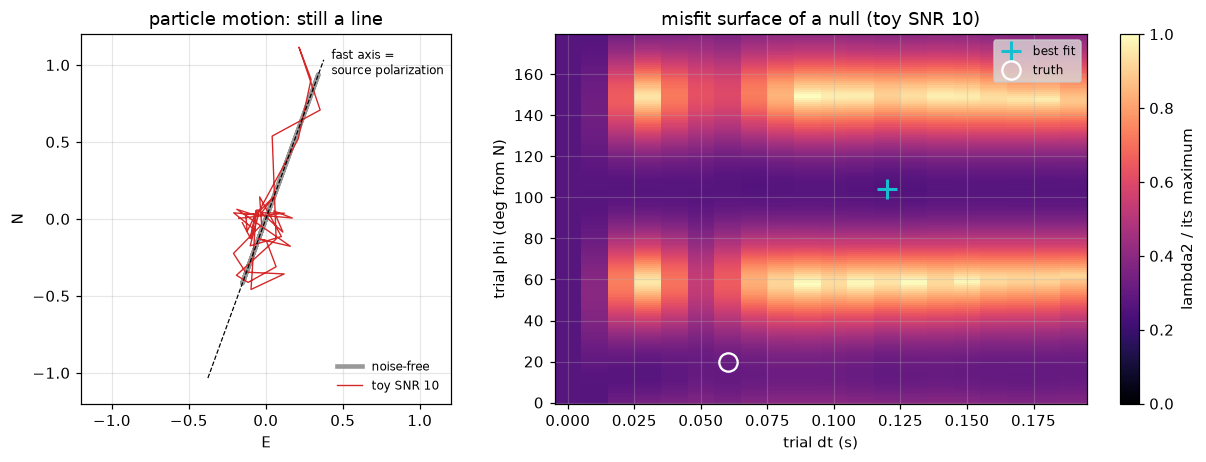

In [10]:
n_null, e_null = pulse * np.cos(np.deg2rad(PHI_TRUE)), pulse * np.sin(np.deg2rad(PHI_TRUE))   # source polarization = phi
n_s, e_s = split(n_null, e_null, PHI_TRUE, DT_TRUE)
nn, ee = add_noise(n_s, e_s, 10)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1, 1.6]})
w_ = (t > -0.15) & (t < 0.25)
axes[0].plot(e_s[w_], n_s[w_], color="0.6", lw=3, label="noise-free")
axes[0].plot(ee[w_], nn[w_], color="tab:red", lw=0.9, label="toy SNR 10")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
a = np.deg2rad(PHI_TRUE)
axes[0].plot([-1.1 * np.sin(a), 1.1 * np.sin(a)], [-1.1 * np.cos(a), 1.1 * np.cos(a)], "k--", lw=0.8)
axes[0].text(1.1 * np.sin(a) + 0.05, 1.0 * np.cos(a), "fast axis =\nsource polarization", fontsize=8)
axes[0].set(aspect="equal", xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), xlabel="E", ylabel="N", title="particle motion: still a line")
im = show_grid(axes[1], misfit(nn, ee), "misfit surface of a null (toy SNR 10)")
fig.colorbar(im, ax=axes[1], label="lambda2 / its maximum")
axes[1].legend(loc="upper right", fontsize=8, facecolor="0.85")
plt.tight_layout()

The particle motion stays a line along the source polarization, and the misfit surface is low along whole lines rather than at one point: along phi equal to the source polarization (20 degrees) and 90 degrees from it (110), for every dt, and along dt = 0 for every phi (an unsplit wave needs no correction, whatever the trial axis). Between those troughs, 45 degrees from the source polarization, are bright ridges: a trial axis there puts equal energy on both components, and any wrong delay opens a loop. So neither phi nor dt is constrained; the grid search returns a point anyway (here phi 104, dt 0.12 s), and its formal errors can look small (the real null of section 10 has errors of 3 degrees and 0.005 s). A **null** is a measurement whose source polarization is nearly parallel or perpendicular to the fast axis: it carries information (that geometry) but not a fast direction.

For a local earthquake the source polarization is set by the earthquake's **focal mechanism**: the orientation of the fault plane and the direction it slipped. Each direction out of the source gets S waves of a different polarization, so different earthquakes, and the same earthquake seen from different stations, give different source polarizations. In a real dataset a null therefore shows up as phi close to the source polarization or perpendicular to it. In teleseismic SKS splitting the source polarization is the back azimuth (the conversion to S at the core sets it), which is why the back azimuth is often used as the null test; for local S waves the two are different things. SWSPy estimates the source polarization of every measurement (`measure.Measurement.src_pol`), and section 9 compares it with the back azimuth at STAR.

## 7. The geometry of a real measurement

The synthetic assumed a wave coming straight up. At STAR the earthquakes are a few km away and a few km down, so the rays arrive at an angle. Two things follow: the free surface distorts S waves that arrive too steeply slanted (the shear-wave window), and the measurement has to be made in a frame that follows the ray (LQT).

### Where the rays come from

The **incidence angle** of a ray is its angle from the vertical where it reaches the station (notebook 03, section 3). A straight line from earthquake to station gives a first estimate. Rock gets faster with depth, though, so rays bend: by Snell's law a ray entering slower rock turns towards the vertical, and rays arrive steeper than the straight line. The research pipeline traces rays through a 3-D velocity model to get the angle (README; the code is not in this repo), and stores it as `incidence_angle`.

The figure is a vertical slice from STAR towards the swarm. The curved ray is a sketch: a speed that grows linearly with depth bends rays into circular arcs, and the gradient is chosen so that the ray from the median event arrives at the median ray-traced angle. The red lines are explained in the next subsection.

901 events: median 2.16 km away and 3.58 km below STAR; a straight line from there arrives 31.2 deg from vertical, the ray-traced angle is 26.8 deg (median)
critical angle for Vp/Vs = 1.73: 35.3 deg; the pipeline's gate: 45 deg


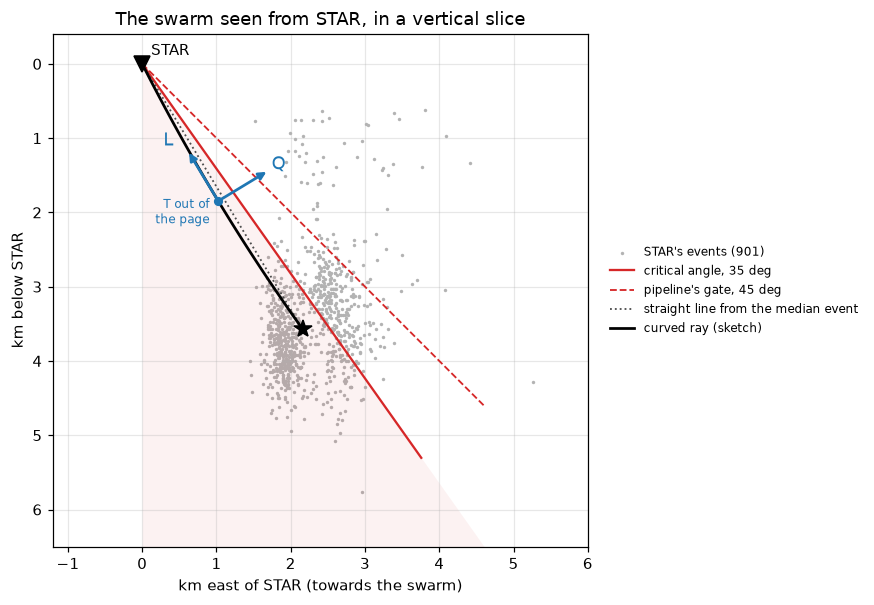

In [11]:
from obspy.geodetics import gps2dist_azimuth
VP_VS = 1.73                                                     # the research model's Vp/Vs (README)
critical = np.degrees(np.arcsin(1 / VP_VS))                      # the critical angle: the edge of the shear-wave window
gate_inc = quality.PreGates().incidence_max_deg                  # the pipeline's incidence gate (45 deg)

lat, lon, elev = data.station_coords("STAR")
geo = cat.merge(res_o[["evid", "incidence_angle"]], on="evid").dropna(subset=["incidence_angle"])
geo["epi_km"] = [gps2dist_azimuth(lat, lon, a, b)[0] / 1000 for a, b in zip(geo.event_lat, geo.event_lon)]
geo["below_km"] = geo.event_depth + elev / 1000                  # catalog depth (below sea level) + STAR's elevation
geo["straight_deg"] = np.degrees(np.arctan2(geo.epi_km, geo.below_km))
xs, zs, i_ray = geo.epi_km.median(), geo.below_km.median(), geo.incidence_angle.median()
print(f"{len(geo)} events: median {xs:.2f} km away and {zs:.2f} km below STAR; a straight line from there arrives "
      f"{np.degrees(np.arctan2(xs, zs)):.1f} deg from vertical, the ray-traced angle is {i_ray:.1f} deg (median)")
print(f"critical angle for Vp/Vs = {VP_VS}: {critical:.1f} deg; the pipeline's gate: {gate_inc:.0f} deg")

# a sketch of a curved ray: speed growing linearly with depth bends rays into circular arcs; the gradient is
# chosen so that the ray from the median event arrives at the median ray-traced angle
h = np.tan(np.deg2rad(i_ray)) * (xs ** 2 + zs ** 2) / (2 * (xs - zs * np.tan(np.deg2rad(i_ray))))   # v0 / gradient, km
xc, zc = (xs ** 2 + zs ** 2 + 2 * zs * h) / (2 * xs), -h                                            # circle centre
rho = np.hypot(xc, zc)
ang = np.linspace(np.arctan2(-zc, -xc), np.arctan2(zs - zc, xs - xc), 100)
ray_x, ray_z = xc + rho * np.cos(ang), zc + rho * np.sin(ang)

fig, ax = plt.subplots(figsize=(10.5, 5.6))
ax.scatter(geo.epi_km, geo.below_km, s=5, color="0.7", lw=0, label=f"STAR's events ({len(geo)})")
for ang_deg, style, label in [(critical, dict(color="tab:red", lw=1.5), f"critical angle, {critical:.0f} deg"),
                              (gate_inc, dict(color="tab:red", lw=1.2, ls="--"), f"pipeline's gate, {gate_inc:.0f} deg")]:
    r = 6.5
    ax.plot([0, r * np.sin(np.deg2rad(ang_deg))], [0, r * np.cos(np.deg2rad(ang_deg))], **style, label=label)
ax.fill_between([0, 6.5 * np.tan(np.deg2rad(critical))], [0, 6.5], 6.5, color="tab:red", alpha=0.06, lw=0)
ax.plot([0, xs], [0, zs], color="0.3", ls=":", lw=1.2, label="straight line from the median event")
ax.plot(ray_x, ray_z, color="k", lw=1.8, label="curved ray (sketch)")
ax.plot(xs, zs, "*", color="k", ms=12)
# the ray frame, drawn at a point halfway along the ray: L along the ray, Q across it in this plane, T out of the page
k = 50
px, pz = ray_x[k], ray_z[k]
lx, lz = ray_x[k - 5] - ray_x[k + 5], ray_z[k - 5] - ray_z[k + 5]          # towards the station: the direction of travel
lx, lz = lx / np.hypot(lx, lz), lz / np.hypot(lx, lz)
for (dx, dz), name in [((lx, lz), "L"), ((-lz, lx), "Q")]:
    ax.annotate("", xy=(px + 0.8 * dx, pz + 0.8 * dz), xytext=(px, pz), arrowprops=dict(arrowstyle="-|>", color="tab:blue", lw=1.8))
    ax.text(px + 0.95 * dx - (0.18 if name == "L" else 0), pz + 0.95 * dz, name, color="tab:blue", fontsize=12, ha="center", va="center")
ax.plot(px, pz, "o", color="tab:blue", ms=5)
ax.text(px - 0.12, pz + 0.3, "T out of\nthe page", color="tab:blue", fontsize=8, ha="right")
ax.plot(0, 0, "v", color="k", ms=11, clip_on=False); ax.text(0.12, -0.12, "STAR", fontsize=10)
ax.set(xlim=(-1.2, 6), ylim=(6.5, -0.4), aspect="equal", xlabel="km east of STAR (towards the swarm)", ylabel="km below STAR",
       title="The swarm seen from STAR, in a vertical slice")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8, frameon=False)
plt.tight_layout()

STAR's 901 events with a ray-traced angle lie a median 2.16 km east of the station and 3.58 km below it (taking the catalog's depths as below sea level and STAR at 3365 m). A straight line from there arrives 31.2 degrees from vertical; the ray-traced angle is 26.8 degrees (median), because the ray steepens as it climbs into slower rock. Most of the swarm lies inside the red cone even along straight lines, and the curved rays arrive steeper still: by the ray-traced angles, 82 percent of STAR's events are inside the critical angle and 94 percent inside the 45-degree gate (the table at the end of this section). The blue arrows are the ray frame, described below.

### Why there is a window: the free surface

The ground surface is a **free surface**: nothing above it pushes back, so a wave arriving from below is reflected, and what the seismometer records is the incoming wave plus its reflections. Split the S wave into two parts:

- **SH**, the part shaking horizontally across the plane of the ray (in the figure above, in and out of the page). It reflects as SH only, and the surface simply moves twice as much as the incoming wave, at every angle.
- **SV**, the part shaking within the plane of the ray. It reflects partly as SV and partly as a converted P wave, and how the two add up at the surface depends on the incidence angle.

Beyond the **critical angle**, sin(angle) = Vs / Vp, the converted P wave can no longer travel away from the surface; it clings to it, and the SV part of the surface motion is shifted in phase relative to the SH part. A phase shift between two components is exactly what splitting looks like, so the free surface can fake a split. The cone of incidence angles inside the critical angle is the **shear-wave window** (Evans, 1984; Booth & Crampin, 1985). With the research model's Vp/Vs of 1.73 it is 35.3 degrees.

The cell solves the reflection for a plane wave on a flat surface (the two zero-traction conditions, a 2x2 linear system; Aki & Richards, 2002, chapter 5) and records an *unsplit* S pulse polarized halfway between SV and SH.

20 deg: horizontal SV 1.82 (SH 2.00), phase shift  0.0 deg, unsplit S: lambda2/lambda1 = 0.000
30 deg: horizontal SV 1.73 (SH 2.00), phase shift  0.0 deg, unsplit S: lambda2/lambda1 = 0.000
34 deg: horizontal SV 2.13 (SH 2.00), phase shift  0.0 deg, unsplit S: lambda2/lambda1 = 0.000
38 deg: horizontal SV 1.47 (SH 2.00), phase shift 77.0 deg, unsplit S: lambda2/lambda1 = 0.461
40 deg: horizontal SV 0.74 (SH 2.00), phase shift 85.2 deg, unsplit S: lambda2/lambda1 = 0.137
45 deg: horizontal SV 0.00 (SH 2.00), phase shift 90.0 deg, unsplit S: lambda2/lambda1 = 0.000
50 deg: horizontal SV 0.29 (SH 2.00), phase shift 87.7 deg, unsplit S: lambda2/lambda1 = 0.022
largest lambda2/lambda1: 0.52 at 37.5 deg; the real split of section 2: 0.25


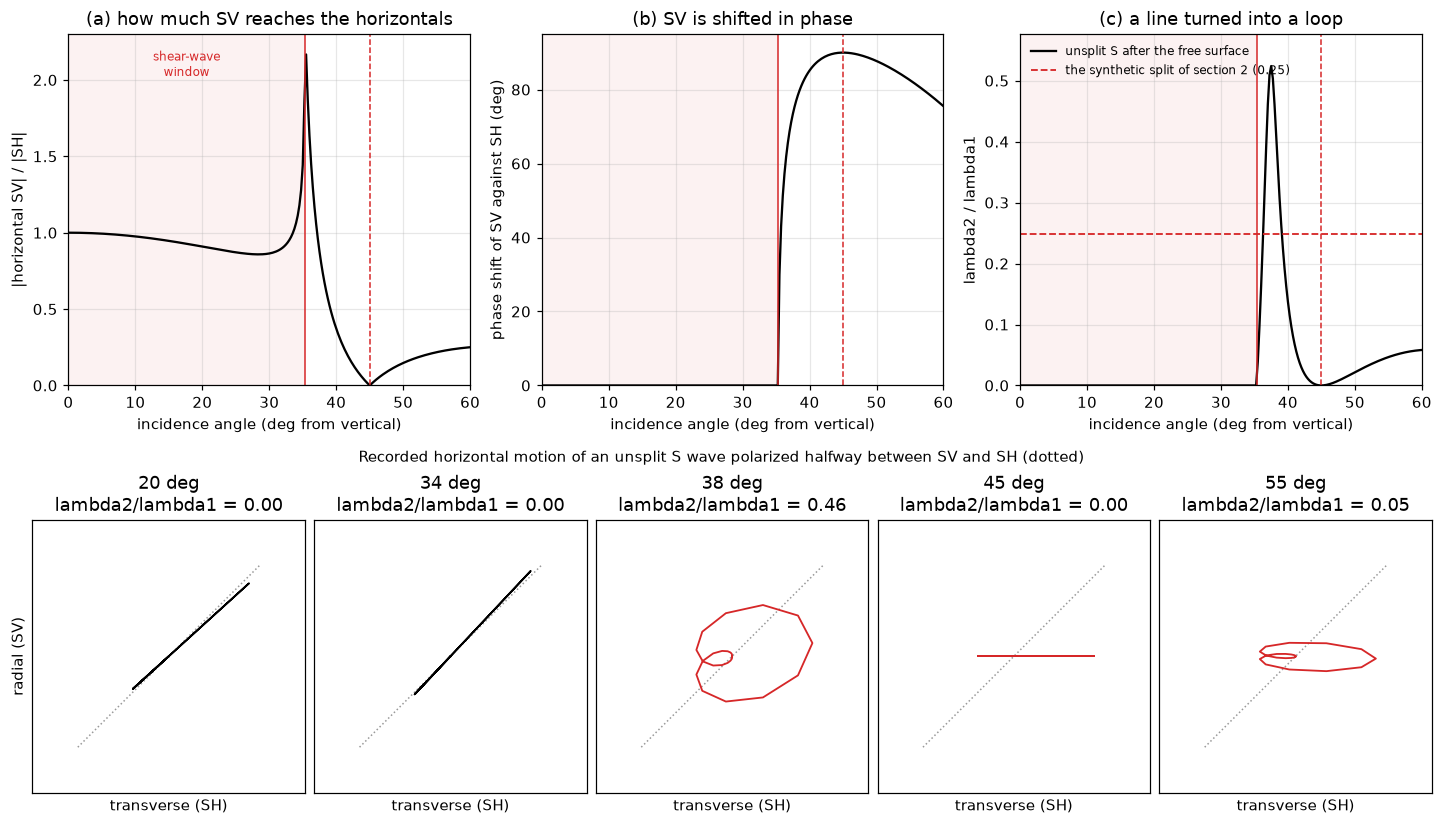

In [12]:
from scipy.signal import hilbert

def free_surface_sv(inc_deg, vp_vs=VP_VS):
    """Horizontal and vertical surface displacement for a unit plane SV wave reaching a flat free surface
    from below at inc_deg from vertical (density and S speed 1). An SH wave gives (2, 0) at every angle.
    Solves the two zero-traction conditions for the reflected P and SV; complex beyond the critical angle."""
    beta, alpha = 1.0, vp_vs
    lam, mu = alpha ** 2 - 2 * beta ** 2, beta ** 2
    p = np.sin(np.deg2rad(inc_deg)) / beta                   # horizontal slowness, the same for every wave
    eta_a = np.sqrt(1 / alpha ** 2 - p ** 2 + 0j)            # vertical slowness of P: imaginary past the critical angle
    eta_b = np.sqrt(1 / beta ** 2 - p ** 2 + 0j)
    waves = {"SV in": (-eta_b, beta * np.array([eta_b, p])),  # (vertical slowness, polarization (x, z)); z down
             "P out": (eta_a, alpha * np.array([p, eta_a])),
             "SV out": (eta_b, beta * np.array([eta_b, -p]))}
    def traction(q, d):                                      # (sigma_xz, sigma_zz) on the surface, common factors dropped
        return np.array([mu * (q * d[0] + p * d[1]), lam * (p * d[0] + q * d[1]) + 2 * mu * q * d[1]])
    A = np.column_stack([traction(*waves["P out"]), traction(*waves["SV out"])])
    r_p, r_s = np.linalg.solve(A, -traction(*waves["SV in"]))
    u = waves["SV in"][1] + r_p * waves["P out"][1] + r_s * waves["SV out"][1]
    return u[0], u[1]

def recorded(inc_deg, pol_deg=45.0, x=pulse):
    """Radial and transverse surface motion of an unsplit S pulse polarized pol_deg from SV towards SH."""
    ux, _ = free_surface_sv(inc_deg)
    radial = np.real(np.conj(ux) * hilbert(x)) * np.cos(np.deg2rad(pol_deg))   # a constant phase shift on every frequency
    transverse = 2 * x * np.sin(np.deg2rad(pol_deg))
    return radial, transverse

def flatness(a, b):
    """lambda2 / lambda1 of two components: 0 for a line, 1 for a circle."""
    lam = np.linalg.eigvalsh(np.cov(np.vstack([a, b])))
    return lam[0] / lam[1]

incs = np.arange(0, 60.01, 0.25)
U = np.array([free_surface_sv(i)[0] for i in incs])
shift = np.mod(-np.degrees(np.angle(U)), 180)                  # phase shift of SV against SH; a sign flip (180) is not a shift
shift = np.minimum(shift, 180 - shift)
fake = np.array([abs(flatness(*recorded(i))) for i in incs])
real = flatness(n1[win], e1[win])                              # the split pulse of section 2, for comparison
fig = plt.figure(figsize=(13, 7.4), layout="constrained")
top_, bottom_ = fig.subfigures(2, 1, height_ratios=[1.15, 1])
top = top_.subplots(1, 3)
top[0].plot(incs, np.abs(U) / 2, color="k")
top[0].set(ylabel="|horizontal SV| / |SH|", ylim=(0, 2.3), title="(a) how much SV reaches the horizontals")
top[1].plot(incs, shift, color="k")
top[1].set(ylabel="phase shift of SV against SH (deg)", ylim=(0, 95), title="(b) SV is shifted in phase")
top[2].plot(incs, fake, color="k", label="unsplit S after the free surface")
top[2].axhline(real, color="tab:red", ls="--", lw=1.2, label=f"the synthetic split of section 2 ({real:.2f})")
top[2].set(ylabel="lambda2 / lambda1", ylim=(0, 1.1 * max(fake.max(), real)), title="(c) a line turned into a loop")
top[2].legend(frameon=False, fontsize=8, loc="upper left")
for ax in top:
    ax.axvspan(0, critical, color="tab:red", alpha=0.06, lw=0)
    ax.axvline(critical, color="tab:red", lw=1); ax.axvline(gate_inc, color="tab:red", lw=1, ls="--")
    ax.set(xlabel="incidence angle (deg from vertical)", xlim=(0, 60))
top[0].text(critical / 2, 2.2, "shear-wave\nwindow", ha="center", va="top", color="tab:red", fontsize=8)
bottom = bottom_.subplots(1, 5)
for ax, inc in zip(bottom, [20, 34, 38, 45, 55]):
    rad, tra = recorded(inc)
    ax.plot([-1.6, 1.6], [-1.6, 1.6], color="0.6", ls=":", lw=1)      # the polarization that arrived
    ax.plot(tra[win], rad[win], color="tab:red" if inc > critical else "k", lw=1.2)
    ax.set(aspect="equal", xlim=(-2.4, 2.4), ylim=(-2.4, 2.4), xticks=[], yticks=[], xlabel="transverse (SH)",
           title=f"{inc} deg\nlambda2/lambda1 = {abs(flatness(rad[win], tra[win])):.2f}")
bottom[0].set_ylabel("radial (SV)")
bottom_.suptitle("Recorded horizontal motion of an unsplit S wave polarized halfway between SV and SH (dotted)", fontsize=10)
for inc in (20, 30, 34, 38, 40, 45, 50):
    ux, uz = free_surface_sv(inc)
    i_ = np.argmin(np.abs(incs - inc))
    print(f"{inc:2d} deg: horizontal SV {abs(ux):.2f} (SH 2.00), phase shift {shift[i_]:4.1f} deg, "
          f"unsplit S: lambda2/lambda1 = {fake[i_]:.3f}")
print(f"largest lambda2/lambda1: {fake.max():.2f} at {incs[np.argmax(fake)]:.1f} deg; the real split of section 2: {real:.2f}")

- **Inside the window** (below 35.3 degrees) the SV part reaches the horizontals with no phase shift. Its size changes (1.82 times the incoming amplitude at 20 degrees, 1.73 at 30, against 2 for SH), which rotates the apparent polarization a little, but the motion stays a line: lambda2 / lambda1 is 0.
- **Just beyond it** the SV part is shifted by up to 90 degrees in phase and the line opens into a loop: at 38 degrees lambda2 / lambda1 is 0.46, and the largest is 0.52 at 37.5 degrees, twice the 0.25 of the synthetic split of section 2 (a real 0.06 s delay). A splitting measurement would happily report a delay here.
- **At 45 degrees** the SV part vanishes from the horizontals altogether (for any rock, not only this Vp/Vs), and every S wave looks purely transverse: a line again, but in the wrong direction. Beyond that the loop reopens, more weakly (0.05 at 55 degrees).

So the pipeline's gate at 45 degrees (`quality.PreGates().incidence_max_deg`) is wider than the window this flat-surface calculation gives. That is a common allowance: rock just below the surface is slower than any velocity model resolves, which bends rays towards the vertical just before they arrive, and real wavefronts are curved, which blurs the edge (Booth & Crampin, 1985). Whether 45 is right for Rainier is a threshold question for notebook 07; at STAR it hardly matters, since 94 percent of the rays arrive within 45 degrees and 82 percent within the window (35.3 degrees).

### The ray frame: LQT

An S wave shakes the ground perpendicular to its ray. For a ray straight up that plane is horizontal, and north and east hold the whole S wave, as in the synthetic. For a slanted ray the plane is tilted: part of the SV motion lands on the vertical component, and the two horizontals see a squashed version of the rest. So the pipeline measures in the **ray frame**, **LQT**:

- **L** along the ray (the direction P waves shake);
- **Q** perpendicular to the ray, in the vertical plane through earthquake and station (the SV direction);
- **T** perpendicular to both, horizontal (the SH direction).

SWSPy rotates Z, N and E into L, Q and T using the back azimuth and the ray-traced incidence angle (`measure.SwsParams().coord_system` is `"LQT"`; ObsPy's `Stream.rotate("ZNE->LQT", ...)` does the same), searches for phi in the Q-T plane, and reports it twice: **phi from Q**, measured clockwise from Q, and phi from north, which is phi from Q plus the back azimuth (section 9 shows one). For a ray straight up, Q points horizontally along the back azimuth and the two are the same measurement; for a slanted ray the conversion is an approximation, good to a few degrees at STAR's angles. The rotation does not undo the free surface: that is what the window is for.

One caveat about STAR. If the rotation is right, P should arrive almost entirely on L. On STAR's corrected components it does not: the P wave looks more horizontal than the ray-traced angle says (README, *Known facts*), and that is not yet explained.

### Which stations are inside the window?

The same question for every station in `results/`. A station farther from the swarm sees rays that are less steep, because the swarm is only a few km deep.

,km from swarm,events,median angle,inside window,above gate,fail_incidence,measured,filtered
station,,,,,,,,
STAR,2.2,901,26.8,82%,6%,47,659,194
RCM,3.0,507,41.2,20%,33%,153,274,32
MILD,4.8,681,51.2,0%,80%,546,107,24
OBSR,6.7,139,61.7,0%,99%,137,1,0
RER,7.0,450,67.7,0%,100%,405,0,0
PARA,7.3,749,68.7,0%,100%,746,0,0
COPP,7.7,348,67.7,0%,100%,347,0,0
PANH,9.4,414,68.7,0%,100%,413,0,0
LON,11.6,1168,70.2,0%,100%,376,670,38


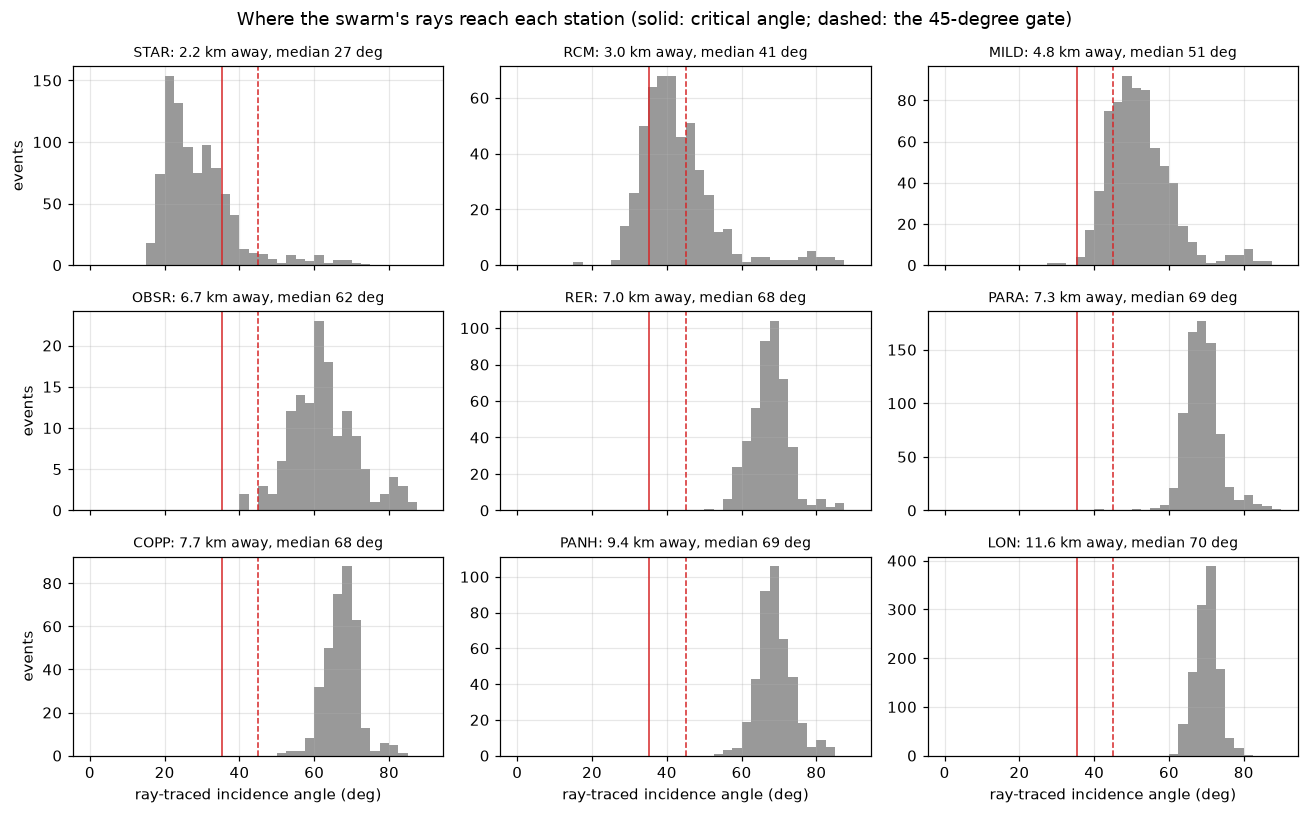

In [13]:
order = ["STAR", "RCM", "MILD", "OBSR", "RER", "PARA", "COPP", "PANH", "LON"]
allres = {s: pd.read_csv(paths.station_results_csv(s, oriented=(s == "STAR"))) for s in order}
stations = data.load_stations().set_index("station")
fig, axes = plt.subplots(3, 3, figsize=(12, 7.5), sharex=True)
rows_ = []
for ax, s in zip(axes.flat, order):
    r = allres[s]
    inc = r.incidence_angle.dropna()
    epi = np.median([gps2dist_azimuth(stations.loc[s, "lat"], stations.loc[s, "lon"], a, b)[0] / 1000
                     for a, b in zip(cat.event_lat, cat.event_lon)])
    ax.hist(inc, bins=np.arange(0, 91, 2.5), color="0.6")
    ax.axvline(critical, color="tab:red", lw=1); ax.axvline(gate_inc, color="tab:red", lw=1, ls="--")
    ax.set_title(f"{s}: {epi:.1f} km away, median {inc.median():.0f} deg", fontsize=9)
    rows_.append({"station": s, "km from swarm": round(epi, 1), "events": len(inc), "median angle": round(inc.median(), 1),
                  "inside window": f"{(inc <= critical).mean():.0%}", "above gate": f"{(inc > gate_inc).mean():.0%}", "fail_incidence": int((r.stage == "fail_incidence").sum()),
                  "measured": len(quality.successful(r)), "filtered": len(quality.post_filtered(r))})
for ax in axes[-1]:
    ax.set_xlabel("ray-traced incidence angle (deg)")
for ax in axes[:, 0]:
    ax.set_ylabel("events")
fig.suptitle("Where the swarm's rays reach each station (solid: critical angle; dashed: the 45-degree gate)")
plt.tight_layout()
pd.DataFrame(rows_).set_index("station")

The incidence angle grows with distance, and the window closes fast. At STAR (2.2 km away) the median ray arrives 26.8 degrees from vertical and 6 percent of events are above 45. At RCM (3.0 km) the median is 41 degrees and a third are above the gate; at MILD (4.8 km) 80 percent are. From 6.7 km out (OBSR, RER, PARA, COPP, PANH) 99 to 100 percent of rays arrive more than 45 degrees from vertical, which is why those stations have no measurements (stage `fail_incidence`). LON is the exception in the table: all its ray-traced angles are above 45, yet it has 670 measurements, because its run was gated on the angle measured from the P wave instead (notebook 06, exercise 2). Its measurements rest on the opposite assumption from everyone else's.

For the project this is the main limit of the permanent network: only the two or three closest stations see the swarm through the window. The 240 nodes of 2025, some of them close to the summit, are the way out (README, *Winter quarter*).

## 8. From the synthetic to STAR: periods and the dt grid

Two numbers tie the synthetic to STAR's measurements. The first is the period of the wave. The filter bank chooses a band for each event (notebook 03, section 6), and the dominant period of the filtered S wave is mostly set by that band: 0.19 s in the 1-5 Hz band that most STAR events choose, 0.115 s at 5-10 Hz (notebook 03, exercise 4). The second is the grid: SWSPy tries a delay by shifting each component half of it, rounded down to whole samples, so at 100 Hz it can only report dt in steps of 0.02 s (`measure.dt_step`).

Left: a synthetic pulse with each of STAR's two common periods, split by the same 0.06 s, and lambda2 / lambda1 (what SWSPy minimizes) along the true phi, every 0.01 s and on SWSPy's grid. The dotted lines are the cycle-skip limits, half the dominant period (`quality.PostFilter().dt_period_fraction`). Right: what STAR's filtered measurements actually report, by band.

1-5 Hz: N = 383 measured events, median dominant period 0.190 s, cycle-skip limit 0.095 s; toy lambda2/lambda1 at dt = 0.00: 0.40, 0.02: 0.63, 0.04: 0.14, 0.06: 0.00, 0.08: 0.14, 0.10: 0.63, 0.12: 0.40
5-10 Hz: N = 114 measured events, median dominant period 0.115 s, cycle-skip limit 0.058 s; toy lambda2/lambda1 at dt = 0.00: 0.30, 0.02: 0.31, 0.04: 0.42, 0.06: 0.00, 0.08: 0.42, 0.10: 0.31, 0.12: 0.30


filter_band,"(1.0, 5.0)","(5.0, 10.0)",other
dt,,,
0.02,5,28,10
0.04,4,3,5
0.06,108,0,8
0.08,19,0,4


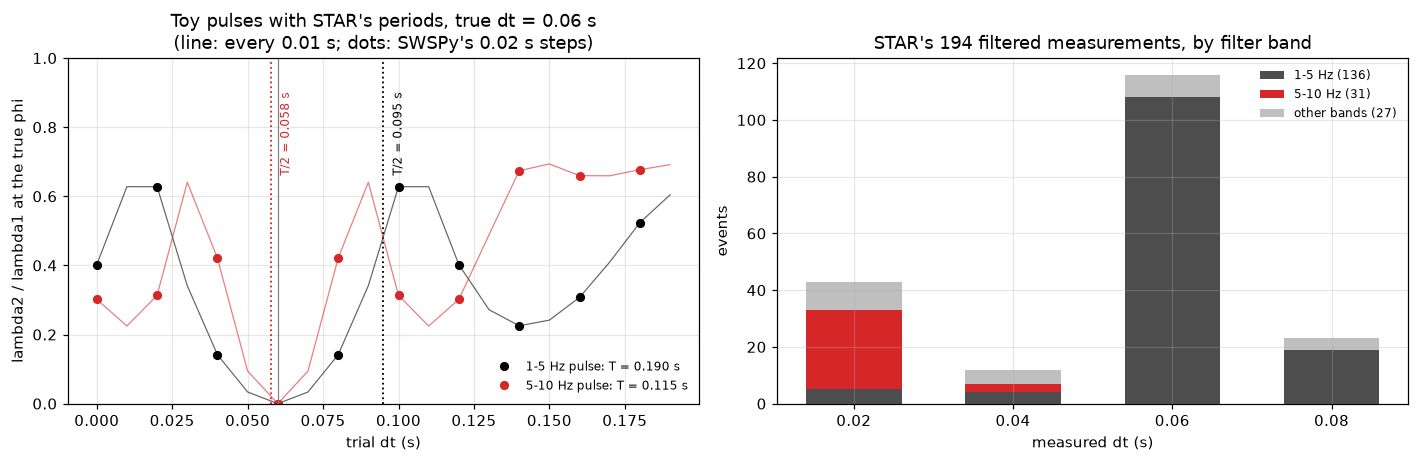

In [14]:
step = measure.dt_step(fs)                                                     # SWSPy's dt spacing: 0.02 s at 100 Hz
dts_swspy = np.arange(0, measure.SwsParams().max_t_shift_s, step)
ok_o = quality.successful(res_o)
T_band = ok_o.groupby("filter_band").dominant_period.median()
star_bands = {"1-5 Hz": "(1.0, 5.0)", "5-10 Hz": "(5.0, 10.0)"}

def make_split(src=src_pol, f0=8.0, phi=PHI_TRUE, dt=DT_TRUE):
    """A noise-free split Ricker pulse, source polarization src (deg), peak frequency f0 (Hz)."""
    p_ = ricker(t, f0)
    return split(p_ * np.cos(np.deg2rad(src)), p_ * np.sin(np.deg2rad(src)), phi, dt)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
i_true = int(np.flatnonzero(phis == PHI_TRUE)[0])
for (name, key), c in zip(star_bands.items(), ["k", "tab:red"]):
    T = T_band[key]
    n_, e_ = make_split(f0=1 / T)
    fine = misfit(n_, e_, ratio=True)[i_true]                                  # every 0.01 s
    coarse = misfit(n_, e_, dts=dts_swspy, ratio=True)[i_true]                 # SWSPy's 0.02 s steps
    axes[0].plot(dts, fine, color=c, lw=0.8, alpha=0.6)
    axes[0].plot(dts_swspy, coarse, "o", color=c, ms=5, label=f"{name} pulse: T = {T:.3f} s")
    axes[0].axvline(T / 2, color=c, ls=":", lw=1.2)
    axes[0].text(T / 2 + 0.003, 0.9, f"T/2 = {T / 2:.3f} s", color=c, fontsize=8, rotation=90, va="top")
    print(f"{name}: N = {(ok_o.filter_band == key).sum()} measured events, median dominant period {T:.3f} s, cycle-skip limit {T / 2:.3f} s; "
          f"toy lambda2/lambda1 at dt = " + ", ".join(f"{d_:.2f}: {v_:.2f}" for d_, v_ in zip(dts_swspy, coarse) if d_ <= 0.125))
axes[0].axvline(DT_TRUE, color="0.5", lw=0.8)
axes[0].set(xlabel="trial dt (s)", ylabel="lambda2 / lambda1 at the true phi", ylim=(0, 1),
            title=f"Toy pulses with STAR's periods, true dt = {DT_TRUE} s\n(line: every 0.01 s; dots: SWSPy's 0.02 s steps)")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")

counts = pd.crosstab(good.dt.round(2), good.filter_band.where(good.filter_band.isin(star_bands.values()), "other"))
x_ = np.arange(len(counts))
bottom = np.zeros(len(counts))
for col, c, label in [("(1.0, 5.0)", "0.3", "1-5 Hz"), ("(5.0, 10.0)", "tab:red", "5-10 Hz"), ("other", "0.75", "other bands")]:
    axes[1].bar(x_, counts[col], bottom=bottom, color=c, width=0.6, label=f"{label} ({counts[col].sum()})")
    bottom += counts[col].to_numpy()
axes[1].set(xticks=x_, xticklabels=[f"{v:.2f}" for v in counts.index], xlabel="measured dt (s)", ylabel="events",
            title=f"STAR's {len(good)} filtered measurements, by filter band")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
counts

Both pulses put the minimum at the true 0.06 s, but the valleys differ. With the 1-5 Hz period the valley is wide (lambda2 / lambda1 is 0.14 at 0.04 and at 0.08 s), so the neighbouring delays fit almost as well and noise moves the answer by a step easily; the shorter 5-10 Hz period gives a narrow valley (0.42 at the same delays). Both have shallower secondary minima about half a period either side of the truth, the candidates for a cycle skip. That is the trade-off of notebook 03, section 8: a longer period resolves a delay less sharply.

The cycle-skip limit is the bigger difference. At 1-5 Hz it is 0.095 s, comfortably above STAR's delays. At 5-10 Hz it is 0.058 s, *below* the 0.06 s that most STAR events measure. A 5-10 Hz event whose wave really is delayed by 0.06 s, measured perfectly, is rejected as a cycle skip.

The right panel shows the result. 108 of the 136 filtered 1-5 Hz events report 0.06 s; 28 of the 31 filtered 5-10 Hz events report 0.02 s and none reports more than 0.04. The four bars are the four clumps of the percent-anisotropy histogram in section 1. So in the filtered set, dt partly labels the filter band (README, *Known facts*). Exercise 2 asks how much of that the cut causes.

## 9. A real split at STAR

Now the real thing, with the pipeline's own measurement (`measure.measure_event`, the function notebook 05 takes apart). Event 62136457 is a typical good STAR measurement: its fast direction is within a degree of the station mean, its dt is the common 0.06 s, its Q_w is 1 (section 10), and it passes every cut. It is measured on the corrected components with its stored ray-traced incidence angle. Left: the filtered N and E around the S pick, with the span of SWSPy's analysis windows. Middle: the particle motion in the widest window, before and after the split is removed (`remove_splitting`, SWSPy's own correction). Right: SWSPy's misfit surface, averaged over its windows, drawn as the synthetic's were, with phi converted from Q to north.

evid 62136457: M 0.68, band (1.0, 5.0) Hz, SNR 9.7, dominant period 0.190 s, incidence 19.9 deg, back azimuth 94.2 deg
phi = -60 deg from Q + back azimuth 94.2 = 34.2 deg from N;  dt = 0.06 s;  errors 6 deg, 0.01 s;  Q_w = 1.00;  source polarization 64 deg
same as the results file: True


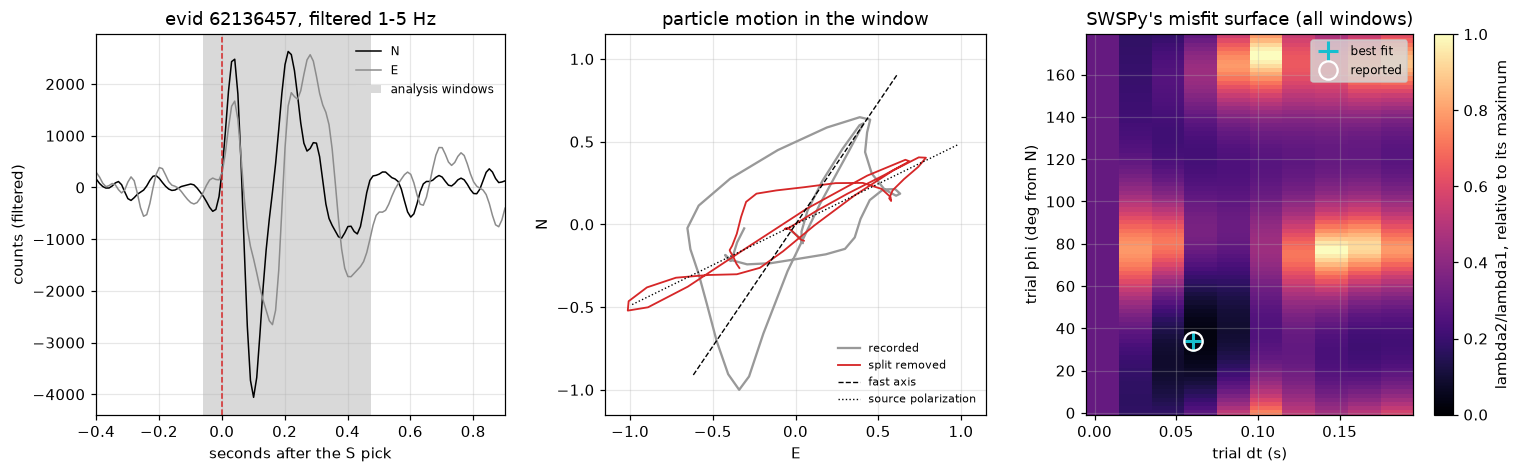

In [15]:
from swspy.splitting.split_windowcheck import remove_splitting
EVID = 62136457                                 # a typical good STAR measurement: phi near the station mean, dt 0.06 s, Q_w 1
ref_row = good.set_index("evid").loc[EVID]
row = cat[cat.evid == EVID].iloc[0]
ev = data.get_event_stream("STAR", row, allow_download=False)              # true Z, N, E (notebook 02)
m = measure.measure_event(row, ev, "STAR", lat, lon, incidence_angle=ref_row.incidence_angle)
so = m.splitting_object
r0 = so.sws_result_df.iloc[0]
print(f"evid {EVID}: M {row.event_magnitude}, band {m.filter_band} Hz, SNR {m.snr_horizontal:.1f}, "
      f"dominant period {m.dominant_period:.3f} s, incidence {m.incidence_angle:.1f} deg, back azimuth {m.back_azimuth:.1f} deg")
print(f"phi = {r0.phi_from_Q:.0f} deg from Q + back azimuth {m.back_azimuth:.1f} = {m.phi:.1f} deg from N;  dt = {m.dt:.2f} s;  "
      f"errors {m.phi_error:.0f} deg, {m.dt_error:.2f} s;  Q_w = {m.quality:.2f};  source polarization {m.src_pol:.0f} deg")
print("same as the results file:", np.isclose(m.phi, ref_row.phi) and np.isclose(m.dt, ref_row["dt"]))

corr = remove_splitting(m.stream_filtered.copy(), r0.phi_from_Q, r0["dt"], m.back_azimuth, m.incidence_angle)
_, _, s_time, _, s_off = measure.pick_offsets(m.stream_filtered, row)
w0, w1 = s_off - so.overall_win_start_pre_fast_S_pick, s_off + so.overall_win_end_post_fast_S_pick   # the widest analysis window
def hz(st, c):
    return st.select(channel=f"??{c}")[0]
fig = plt.figure(figsize=(14, 4.4))
ax = fig.add_subplot(1, 3, 1)
tt_ = hz(m.stream_filtered, "N").times() - s_off
for c, col in [("N", "k"), ("E", "0.55")]:
    ax.plot(tt_, hz(m.stream_filtered, c).data, color=col, lw=1, label=c)
ax.axvspan(w0 - s_off, w1 - s_off, color="0.85", lw=0, label="analysis windows")
ax.axvline(0, color="tab:red", ls="--", lw=1)
ax.set(xlim=(-0.4, 0.9), xlabel="seconds after the S pick", ylabel="counts (filtered)",
       title=f"evid {EVID}, filtered {m.filter_band[0]:g}-{m.filter_band[1]:g} Hz")
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax = fig.add_subplot(1, 3, 2)
i0, i1 = round(w0 * fs), round(w1 * fs)
A = max(np.abs(hz(m.stream_filtered, c).data[i0:i1]).max() for c in "NE")
ax.plot(hz(m.stream_filtered, "E").data[i0:i1] / A, hz(m.stream_filtered, "N").data[i0:i1] / A, color="0.6", lw=1.5, label="recorded")
ax.plot(hz(corr, "E").data[i0:i1] / A, hz(corr, "N").data[i0:i1] / A, color="tab:red", lw=1.2, label="split removed")
for az, style, label in [(m.phi, dict(color="k", ls="--"), "fast axis"), (m.src_pol, dict(color="k", ls=":"), "source polarization")]:
    a = np.deg2rad(az)
    ax.plot([-1.1 * np.sin(a), 1.1 * np.sin(a)], [-1.1 * np.cos(a), 1.1 * np.cos(a)], lw=0.9, **style, label=label)
ax.set(aspect="equal", xlim=(-1.15, 1.15), ylim=(-1.15, 1.15), xlabel="E", ylabel="N", title="particle motion in the window")
ax.legend(frameon=False, fontsize=7, loc="lower right")
ax = fig.add_subplot(1, 3, 3)
g_sw = so.phi_dt_grid_average["STAR"].T[:-1]                               # SWSPy's lambda2/lambda1, averaged over its windows
phi_N = np.mod(so.phis_labels[:-1] + m.back_azimuth, 180)                  # its phi axis is from Q (-90 to 88): add the back azimuth
order_ = np.argsort(phi_N)
im = show_grid(ax, g_sw[order_], "SWSPy's misfit surface (all windows)", truth=None, dts=so.lags_labels, phis=phi_N[order_])
ax.plot(m.dt, np.mod(m.phi, 180), "o", mfc="none", mec="w", ms=12, mew=1.5, label="reported")
fig.colorbar(im, ax=ax, label="lambda2/lambda1, relative to its maximum")
ax.legend(loc="upper right", fontsize=8, facecolor="0.85")
plt.tight_layout()

This is section 2 run backwards on real data:

- **The numbers.** SWSPy found phi = -60 degrees from Q; adding the back azimuth of 94.2 gives 34.2 degrees from north (section 7), the value in the results file. dt is 0.06 s, the formal errors are 6 degrees and 0.01 s (the grid's floor for dt), and Q_w is 1.00. The source polarization is 64 degrees, 30 degrees from the fast axis: a good geometry, far from a null (section 6).
- **The particle motion.** Recorded, it is an open loop; with the split removed it collapses towards a line along the source polarization (dotted), not along the fast axis. Real data do not give the perfect line of the synthetic: the window holds more than one swing of the wave and some of what follows it.
- **The misfit surface** has one dark minimum near (34 degrees, 0.06 s) and the bright stripes of section 3 on either side. It comes in blocks 0.02 s wide: SWSPy labels its trial delays every 0.01 s, but neighbouring pairs are the same shift (section 8).

### Source polarization against back azimuth

The results file does not store the source polarization, so the cell re-measures STAR's 194 filtered events with `measure.remeasure` (about 35 seconds) and compares three directions for each: the fast direction, the source polarization, and the back azimuth (drawn as an axis, as the null and artifact screens use it).

re-measured phi and dt identical to the file: True
angle between phi and the source polarization: median 28 deg (10-90%: 16 to 38); between phi and the back azimuth: median 58 deg
angle between the source polarization and the back azimuth: median 39 deg


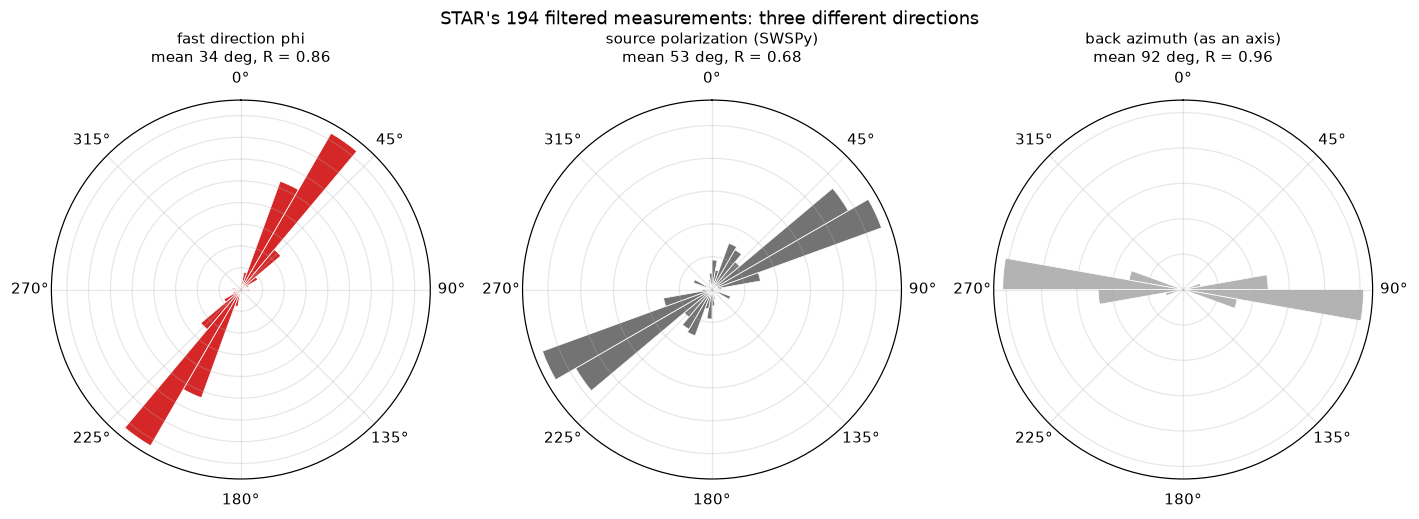

In [16]:
again = measure.remeasure(good, "STAR")          # about 35 s: the results file does not store the source polarization
print("re-measured phi and dt identical to the file:", bool(np.allclose(again.phi, good.phi) and np.allclose(again.dt, good.dt)))
good = good.assign(src_pol=again.src_pol.to_numpy())

def rose(ax, angles, title, color):
    """Axial rose: each angle counted at a and a + 180, in 10-degree bins."""
    a = np.mod(np.asarray(angles, float), 180)
    edges = np.deg2rad(np.arange(0, 361, 10))
    counts_, _ = np.histogram(np.deg2rad(np.concatenate([a, a + 180])), bins=edges)
    ax.bar(edges[:-1], counts_, width=np.deg2rad(10), align="edge", color=color, edgecolor="w", lw=0.5)
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_yticklabels([])
    mean_, R_ = stats.axial_mean(a)
    ax.plot(np.deg2rad([mean_, mean_ + 180]), [counts_.max()] * 2, alpha=0)          # keep the radial scale
    ax.set_title(f"{title}\nmean {mean_:.0f} deg, R = {R_:.2f}", fontsize=10)

fig = plt.figure(figsize=(13, 4.6))
for k, (col, title, color) in enumerate([("phi", "fast direction phi", "tab:red"),
                                         ("src_pol", "source polarization (SWSPy)", "0.45"),
                                         ("back_azimuth", "back azimuth (as an axis)", "0.7")]):
    rose(fig.add_subplot(1, 3, k + 1, projection="polar"), good[col], title, color)
fig.suptitle(f"STAR's {len(good)} filtered measurements: three different directions")
plt.tight_layout()
d_src, d_baz = stats.axial_diff(good.phi, good.src_pol), stats.axial_diff(good.phi, good.back_azimuth)
print(f"angle between phi and the source polarization: median {np.median(d_src):.0f} deg (10-90%: "
      f"{np.percentile(d_src, 10):.0f} to {np.percentile(d_src, 90):.0f}); between phi and the back azimuth: median {np.median(d_baz):.0f} deg")
print(f"angle between the source polarization and the back azimuth: median "
      f"{np.median(stats.axial_diff(good.src_pol, good.back_azimuth)):.0f} deg")

- **Fast directions** cluster tightly: mean 34 degrees, R = 0.86 (R, the mean resultant length, is 1 when all axes agree and 0 when they are spread evenly; notebook 07).
- **Back azimuths** are almost one direction: mean 92 degrees, R = 0.96. The swarm is east of STAR, so every ray comes from the east.
- **Source polarizations** are spread much more widely: mean 53 degrees, R = 0.68. Different earthquakes in the swarm slipped differently, so they sent S waves of different polarization along nearly the same path. They differ from the back azimuth by a median of 39 degrees.

That spread is good news for STAR. The angle between the fast direction and the source polarization has a median of 28 degrees (10 to 90 percent: 16 to 38), close to the 45 degrees where splitting shows most clearly (section 6; exercise 1), while the angle between phi and the back azimuth (median 58) tells you nothing about nulls. For local earthquakes the null screen belongs against the source polarization; against the back azimuth it is an *artifact* check, which is how the channel exchange was found (README). Exercise 1 counts both.

## 10. Optional reading: three textbook cases at AXEC2 (about 15 minutes)

Here are three real measurements made with the same pipeline you will run in notebook 05: SWSPy with the MFAST filter bank, many analysis windows and clustering. They come from Michael's other project, station AXEC2 on the summit caldera of **Axial Seamount**, an ocean-bottom volcano, because that dataset has clean textbook examples of each case. The figures are from `axial-sws/scripts/figure_axec2_mfast_event_*_diagnostics.py`. They were made in July 2026, before the axial-sws project corrected its own component orientations (October 2026): use them for what each case looks like, not for their phi values.

Every figure has the same panels:

- **A**: the three components, the P pick (blue), the S pick (red) and the analysis windows (grey). SWSPy tries 7 window starts and 7 window ends: 49 **analysis windows** in all. With the Rainier pipeline's settings (`measure.SwsParams`) the starts lie 0.06 to 0.03 s before the S pick (twice and once `s_pick_uncertainty`) and the ends 1.5 to 2.5 dominant periods after it.
- **Original / corrected particle motion**: the two horizontal components in the ray frame, Q against T (section 7), before and after removing the best-fitting split.
- **phi-dt parameter space**: the misfit surface of section 3, coloured by the **normalised eigenvalue ratio** lambda2 / lambda1 (low = good fit), with the best solution marked and the cycle-skip limit T_dom / 2 dashed (**T_dom** is the dominant period). phi is measured from Q, not from north. Mind the colours: the good split uses a blue scale in which *light* is a good fit, the other two the magma scale of this notebook, in which *dark* is.
- **DBSCAN clustering**: the answer (phi, dt) from each of the 49 windows. **DBSCAN** is a clustering method that groups points lying close together and leaves isolated points out; SWSPy keeps the largest group (after Teanby et al., 2004). Agreeing windows form one tight cluster.

Each figure also quotes the **rectilinearity**, how close the P wave's motion is to a straight line (1 = perfectly straight; the pipeline's first gate, `PreGates.rectilinearity_min`), and **Q_w**, the quality factor of Wüstefeld et al. (2010). Q_w compares the eigenvalue answer with an independent **cross-correlation** answer (the (phi, dt) at which the fast and slow components look most alike): near +1 means they agree as good splits agree, near -1 that they disagree in the way nulls do. The post-processing filter keeps Q_w >= `quality.PostFilter().qw_min` (0.75).

### A good split

![A high-quality split at AXEC2](images/sws_example_good_split_axec2.png)

Event 298_74456 (21 April 2015): phi 14 degrees from Q, dt 0.030 s, Q_w 1.0, SNR 23, rectilinearity 0.999, incidence 15 degrees. This is what you want every measurement to look like:

- **Particle motion**: an open loop before correction (C) collapses to a nearly straight line after (D), as in section 9.
- **Misfit surface** (B; light = good fit): one small, closed minimum, well to the left of T_dom / 2, with the repeating minima at larger dt (the cycle-skip candidates) clearly worse.
- **Windows** (E, F, G): 41 of 49 windows land in one cluster, and phi and dt barely move from window to window.

### A null

![A null measurement at AXEC2](images/sws_example_null_axec2.png)

Event 12_2753 (31 January 2015): the pipeline reports phi 20 degrees from Q and dt 0.050 s with tiny errors (3 degrees, 0.005 s), at SNR 18 and rectilinearity 0.99. It passes every post-processing cut **except** the quality factor: Q_w = -0.92.

- **Particle motion**: already nearly linear before correction (B), and the "correction" hardly changes it (C). There was little or no splitting to undo: the case of section 6.
- **Misfit surface** (D; dark = good fit): no single closed minimum but two dark bands 90 degrees apart, near 25 and -65 degrees from Q, low at every dt: the source polarization and its perpendicular, as in the synthetic null of section 6. Between them, 45 degrees away, run bright ridges. The best point (20 degrees, 0.05 s) sits at the edge of one band, where every dt fits about equally well, and its formal errors still look small.
- **Windows** (E): the windows agree with each other almost perfectly, because they all see the same unsplit wave.

Without the Q_w cut this precise-looking number would go straight into a rose diagram. A null is information (the source polarization is close to the fast axis or across it), not a fast direction.

### A cycle skip

![A cycle-skipped measurement at AXEC2](images/sws_example_cycle_skip_axec2.png)

Event 16_3842 (31 January 2015): phi -30 degrees from Q, **dt 0.160 s**, Q_w 0.97, SNR 12, rectilinearity 0.99, errors at the grid floor (2 degrees, 0.005 s). The dominant period is 0.160 s, so dt is a whole period: twice the T_dom / 2 limit.

- **Misfit surface** (D): good minima on both sides of the dashed T_dom / 2 line, repeating along dt, the comb of section 8. The best solution sits one full cycle out: the grid search matched each swing of the slow wave with the *next* swing of the fast one.
- **Windows** (E): two clusters, 15 windows near 0.10 to 0.11 s and 30 near 0.16 s, at the same phi. The pipeline picks the bigger one.
- **Particle motion** (B, C): linearised after "correction", because shifting by a whole period also lines the swings up.

Every quality number says this is excellent. Only the rule **dt <= T_dom / 2** removes it, which is why that cut is in the post-processing filter (`quality.PostFilter().dt_period_fraction`) and why the dominant period is recorded for every measurement (notebook 03, section 7).

## 11. Glossary

Terms notebook 03 defined (phi, dt, fast and slow wave, dominant period, cycle skip, SNR, filter bank, P coda, incidence angle) are in its glossary.

| term | meaning | section |
| --- | --- | --- |
| analysis window | the stretch of trace around S that the grid search uses; SWSPy tries 49 of them | 3, 10 |
| anisotropic | with a wave speed that depends on direction | 1 |
| back azimuth | direction from the station towards the earthquake, clockwise from north (notebook 02) | 6, 9 |
| covariance matrix | for two components, their variances and their covariance; its eigenvalues measure motion along and across the main direction | 3 |
| critical angle | incidence angle beyond which a converted P wave cannot leave the free surface: sin(angle) = Vs / Vp | 7 |
| cross-correlation method | finds (phi, dt) by making the corrected fast and slow components look most alike; the second method behind Q_w | 10 |
| DBSCAN | clustering that groups points lying close together; SWSPy uses it on the answers of its windows | 10 |
| eigenvalue method | finds (phi, dt) by making the corrected particle motion as linear as possible (smallest lambda2) | 3 |
| F-test, formal errors | the statistical test that turns the misfit valley into `phi_error` and `dt_error` | 4 |
| focal mechanism | orientation of an earthquake's fault plane and the direction it slipped; sets the source polarization | 6 |
| free surface | the ground surface, where nothing pushes back and waves are reflected | 7 |
| lambda1, lambda2 | larger and smaller eigenvalue of the covariance matrix; lambda2 = 0 for linear motion | 3 |
| linear particle motion | the ground moves back and forth along one line | 2 |
| LQT, ray frame | L along the ray, Q across it in the vertical plane of the ray, T horizontal and across it | 7 |
| maximum horizontal compressive stress | the horizontal direction in which the rock is squeezed hardest; open cracks line up with it | 1 |
| misfit surface | the misfit (here lambda2) over the whole (phi, dt) grid | 3 |
| normalised eigenvalue ratio | lambda2 / lambda1, what SWSPy minimizes | 3, 10 |
| null | a measurement whose source polarization is parallel or perpendicular to the fast axis: no split to measure | 6 |
| particle motion | one component plotted against another: the path the ground traces | 2 |
| percent anisotropy | 100 x dt / S travel time: how much slower the slow wave is, averaged along the path | 1 |
| phi from Q | the fast direction measured clockwise from Q in the ray frame; plus the back azimuth gives phi from north | 7, 9 |
| polarization | the direction in which a wave shakes the ground | 1 |
| Q_w | quality factor comparing the eigenvalue and cross-correlation answers: +1 agree, -1 null-like (Wüstefeld et al., 2010) | 10 |
| rectilinearity | how close the P wave's motion is to a straight line (1 = straight) | 10 |
| shear-wave window | the cone of incidence angles, inside the critical angle, in which the free surface does not distort S waves | 7 |
| source polarization | the direction the S wave shakes before it is split; SWSPy's estimate is `Measurement.src_pol` | 2, 6, 9 |
| SV, SH | the parts of an S wave shaking within the vertical plane of the ray, and horizontally across it | 7 |
| T_dom | the dominant period, as AXEC2's figures label it | 10 |
| travel time | here the S travel time from ray tracing (`travel_time_s`), the denominator of percent anisotropy | 1 |

References in this notebook: Silver, P.G. & Chan, W.W. (1991), *Shear wave splitting and subcontinental mantle deformation*, JGR 96, 16429-16454. Crampin, S. & Peacock, S. (2008), *A review of the current understanding of seismic shear-wave splitting in the Earth's crust and common fallacies in interpretation*, Wave Motion 45, 675-722. Wüstefeld, A., Al-Harrasi, O., Verdon, J.P., Wookey, J. & Kendall, J.-M. (2010), *A strategy for automated analysis of passive microseismic data to image seismic anisotropy and fracture characteristics*, Geophys. Prospect. 58, 755-773. Teanby, N.A., Kendall, J.-M. & van der Baan, M. (2004), *Automation of shear-wave splitting measurements using cluster analysis*, BSSA 94, 453-463. Evans, R. (1984), *Effects of the free surface on shear wavetrains*, Geophys. J. R. astr. Soc. 76, 165-172. Booth, D.C. & Crampin, S. (1985), *Shear-wave polarizations on a curved wavefront at an isotropic free surface*, Geophys. J. R. astr. Soc. 83, 31-45. Aki, K. & Richards, P.G. (2002), *Quantitative Seismology*, 2nd ed., University Science Books, chapter 5. Shelly, D.R., Moran, S.C. & Thelen, W.A. (2013), GRL 40, 1506-1512 (the 2009 structure). Hudson, T.S., Asplet, J. & Walker, A.M. (2023), *Automated shear-wave splitting analysis for single- and multi-layer anisotropic media*, Seismica (SWSPy).

## 12. Exercises

Each one asks a question the project needs answered, with the tools of this lesson. They reuse the functions above (`ricker`, `split`, `misfit`, `best`, `add_noise`, `make_split`, `pipeline_snr`) and the STAR tables `res_o` and `good`.

1. **Is a back-azimuth null screen the right test at STAR?** In the synthetic, sweep the angle between the source polarization and the fast axis (0, 5, 10, 20, 30 and 45 degrees; `make_split(src=...)`) at toy SNR 5 and 10, 100 trials each. How often is phi within 20 degrees of the truth, and how often would a 20-degree null screen around the known source polarization (`stats.near_axis`) flag the answer? Then, at STAR, count the filtered events near their source polarization (`good.src_pol`, section 9) and near their back azimuth. How many are flagged by each, by both, and by chance (`stats.chance_near_axis`)? Does removing either set move the mean fast direction?
2. **Does the cycle-skip cut throw away real delays?** Give the synthetic the dominant periods of STAR's two main bands (`T_band`, section 8), measure on SWSPy's 0.02 s grid with lambda2 / lambda1 and a window as long as SWSPy's (from 0.045 s before the pick to two dominant periods after it), for true delays of 0.02 to 0.08 s at toy SNR 10. How often is the true delay found, and how often does dt <= T/2 reject it? Then count STAR's measurements by band and dt, and those that fail only this cut (`dataclasses.replace(quality.DEFAULT_POST, dt_period_fraction=np.inf)` switches it off). Does the cut explain why 5-10 Hz events report small delays?
3. **Can a timing error alone move phi?** Every window is placed from the S pick. Move the window relative to the pulse by the S-pick jitter SWSPy sweeps over (`SwsParams.s_pick_uncertainty`, either way), by the 40 ms the pipeline's causal filter delays S (notebook 03, exercise 1), by 50 ms either way (what a clock correction applied to the waveforms but not to the picks would do; notebook 04b, section 1) and by 100 ms, with the SWSPy-length window of exercise 2, at toy SNR 5 and 10. Which errors matter, and in which direction? Compare with notebook 07, section 6, where a 0.03 s pick shift changes Q_w for one real event.
4. **How good is the width of the valley as an error bar, and what does Q_w add?** Measure, for each noisy trial, how many degrees of phi have a best lambda2 within 10 percent of the minimum (the valley width), and compare it with the actual error at several SNRs. Then use half the width as a gate at `quality.PostFilter().phi_error_max`: how often is a measurement that passes still wrong? Finally implement SWSPy's cross-correlation search and Q_w on the synthetic and sweep the source-polarization angle as in exercise 1. What did raising the Q_w cut from 0.5 to 0.75 (README) remove, in the synthetic and at STAR?
5. **Is the anisotropy spread along the whole path?** If cracks fill the whole path, dt grows in proportion to travel time; if they sit in a thin layer near the station, it does not. Plot STAR's dt against `travel_time_s` with lines of uniform percent anisotropy, and compute a rank correlation. How much would dt grow across STAR's range of travel times for a uniform anisotropy, compared with SWSPy's dt step? Then compare `travel_time_s` with the catalog's S pick minus origin time: which would you divide by, and what does the choice do to percent anisotropy? What data would answer the question (README, week 8)?

Next: `04b_timing_and_clock_errors.ipynb` (same week): before trusting a window placed from a pick, check the clock. Then `05_single_event_with_swspy.ipynb`, the real thing.

## 13. Example solutions

One way to do each exercise. Try them yourself first. Everything reuses the functions above, and each cell seeds its own random generator so the numbers repeat.

### Exercise 1: is a back-azimuth null screen the right test at STAR?

First the synthetic. "Screened" is the fraction of trials whose recovered phi lies within 20 degrees of the known source polarization or of its perpendicular, which is what a null screen would remove.

toy SNR 5 and 10 are pipeline SNRs of about 2.0 and 3.6 (section 5)
           N      within_tol       median_err      screened      
toy_snr   5    10         5     10         5    10       5     10
offset                                                           
0        100  100       0.39  0.58       28.5  9.0     0.69  0.93
5        100  100       0.47  0.66       25.0  7.0     0.73  0.93
10       100  100       0.49  0.74       21.5  7.0     0.60  0.78
20       100  100       0.63  0.99       15.5  4.0     0.35  0.45
30       100  100       0.74  1.00       10.0  3.0     0.30  0.04
45       100  100       0.85  0.99        9.0  5.0     0.09  0.00


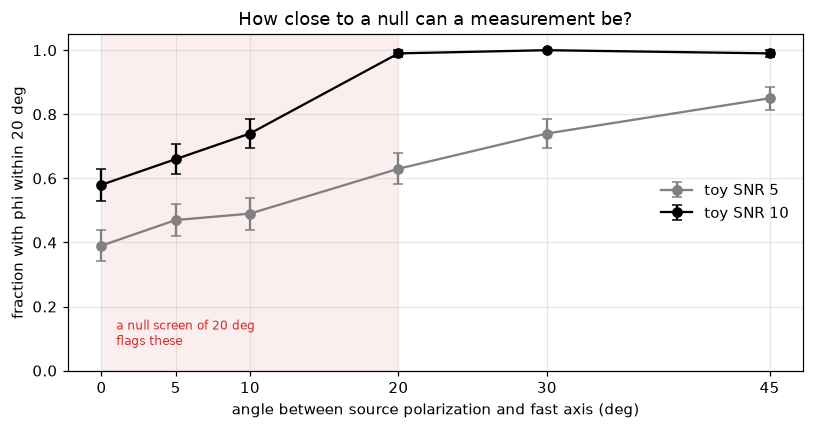

In [17]:
rng = np.random.default_rng(42)
offsets = [0, 5, 10, 20, 30, 45]
rows = []
for snr in (5, 10):
    for off in offsets:
        n_, e_ = make_split(src=PHI_TRUE + off)
        for k in range(100):
            p, d = best(misfit(*add_noise(n_, e_, snr)))
            rows.append({"toy_snr": snr, "offset": off, "phi_err": float(stats.axial_diff(p, PHI_TRUE)),
                         "screened": bool(stats.near_axis(p, PHI_TRUE + off))})   # what a null screen would flag
sweep = pd.DataFrame(rows)
tab = sweep.groupby(["toy_snr", "offset"]).agg(N=("phi_err", "size"), within_tol=("phi_err", lambda x: (x <= TOL_DEG).mean()),
                                              median_err=("phi_err", "median"), screened=("screened", "mean"))
print(f"toy SNR 5 and 10 are pipeline SNRs of about {summary.loc[5, 'pipeline_snr']:.1f} and {summary.loc[10, 'pipeline_snr']:.1f} (section 5)")
print(tab.round(2).unstack(0).to_string())

fig, ax = plt.subplots(figsize=(7.5, 4))
for snr, c in [(5, "0.5"), (10, "k")]:
    g_ = tab.loc[snr]
    ax.errorbar(g_.index, g_.within_tol, yerr=np.sqrt(g_.within_tol * (1 - g_.within_tol) / g_.N), fmt="o-", color=c, capsize=3,
                label=f"toy SNR {snr}")
ax.axvspan(0, 20, color="tab:red", alpha=0.08, lw=0)
ax.text(1, 0.08, "a null screen of 20 deg\nflags these", color="tab:red", fontsize=8)
ax.set(xlabel="angle between source polarization and fast axis (deg)", ylabel=f"fraction with phi within {TOL_DEG:.0f} deg",
       ylim=(0, 1.05), xticks=offsets, title="How close to a null can a measurement be?")
ax.legend(frameon=False, loc="center right")
plt.tight_layout()

At an angle of 0 the wave is a true null and "within 20 degrees of the truth" means little: the troughs run along 20 and 110 degrees (section 6), and the grid lands near one or the other. Now STAR, with the source polarizations re-measured in section 9:

In [18]:
near_src = stats.near_axis(good.phi, good.src_pol)            # the null screen: phi near the source polarization or across it
near_baz = stats.near_axis(good.phi, good.back_azimuth)       # the same test against the back azimuth: an artifact check
print(f"of {len(good)} filtered STAR events: {near_src.sum()} near their source polarization, {near_baz.sum()} near their "
      f"back azimuth, {(near_src & near_baz).sum()} near both; a random axis would be flagged {stats.chance_near_axis():.0%} of the time")
for label, keep in [("all", np.ones(len(good), bool)), ("without the near-source-polarization ones", ~near_src),
                    ("without the near-back-azimuth ones", ~near_baz)]:
    mean_, lo_, hi_, _ = stats.bootstrap_axial_mean(good.phi[keep])
    print(f"  mean phi, {label:42s}: {mean_:5.1f} deg (68% {mean_ + lo_:.1f} to {mean_ + hi_:.1f}), N = {keep.sum()}")

of 194 filtered STAR events: 32 near their source polarization, 57 near their back azimuth, 5 near both; a random axis would be flagged 44% of the time
  mean phi, all                                       :  33.7 deg (68% 32.8 to 34.7), N = 194
  mean phi, without the near-source-polarization ones :  33.5 deg (68% 32.5 to 34.6), N = 162
  mean phi, without the near-back-azimuth ones        :  35.5 deg (68% 34.8 to 36.2), N = 137


**In the synthetic, the measurement degrades smoothly as the source polarization approaches the fast axis.** At toy SNR 10 (pipeline SNR about 3.6) phi is within 20 degrees of the truth in 99 to 100 percent of trials when the two are 20 to 45 degrees apart, and in 58 to 74 percent at 0 to 10 degrees. At toy SNR 5 (pipeline SNR about 2, the gate) the fraction falls from 0.85 at 45 degrees to 0.63 at 20 and 0.39 at 0, so near-nulls become unreliable well before the source polarization is exactly on the axis.

**A null screen removes good measurements as well as bad ones.** At toy SNR 10 it flags 93 percent of trials at 0 and 5 degrees, where it should, but also 45 percent at 20 degrees, where 99 percent of the measurements were right; at 30 degrees it flags 4 percent. A 20-degree screen trades good measurements in the 10-to-25-degree zone for protection against nulls.

**At STAR the two screens test different things.** Of the 194 filtered events, 32 lie within 20 degrees of their source polarization or its perpendicular, 57 within 20 degrees of their back azimuth or its perpendicular, and only 5 are in both; a random axis would be flagged 44 percent of the time, so both counts are below chance. Removing the 32 near-null events moves the mean fast direction from 33.7 to 33.5 degrees, well inside its 68 percent interval (32.8 to 34.7): the nulls do not bias the result. Removing the 57 back-azimuth events moves it to 35.5 (34.8 to 36.2). The back azimuth is nearly the same for every event (section 9), so that screen removes roughly every phi within 20 degrees of east-west or north-south, a slice of the rose, whatever the physics.

So: for local earthquakes the null screen belongs against the source polarization (`stats.near_axis(phi, src_pol)`). The back-azimuth screen is still worth running as an artifact check, because a component error lines phi up with the rays: that is how STAR's channel exchange showed itself (README). Neither belongs in the benchmark as a filter without reporting what it removes.

### Exercise 2: does the cycle-skip cut throw away real delays?

In [19]:
rng = np.random.default_rng(7)
win_sw = lambda T: (t >= S_PICK - 0.045) & (t <= S_PICK + 2 * T)          # mid-range SWSPy window (section 10)
rows = []
for name, key in star_bands.items():
    T = T_band[key]
    for dt_true in (0.02, 0.04, 0.06, 0.08):
        n_, e_ = make_split(f0=1 / T, dt=dt_true)
        for k in range(100):
            p, d = best(misfit(*add_noise(n_, e_, 10), win=win_sw(T), dts=dts_swspy, ratio=True), dts=dts_swspy)
            rows.append({"band": name, "true dt": dt_true, "recovered": abs(d - dt_true) < step / 2,
                         "fails dt <= T/2": d > T * quality.PostFilter().dt_period_fraction})
toy2 = pd.DataFrame(rows).groupby(["band", "true dt"]).mean().unstack(0)
print("toy, SNR 10 (100 trials each): fraction recovering the true dt, and fraction the cycle-skip cut rejects")
print(toy2.round(2).to_string())

toy, SNR 10 (100 trials each): fraction recovering the true dt, and fraction the cycle-skip cut rejects
        recovered         fails dt <= T/2        
band       1-5 Hz 5-10 Hz          1-5 Hz 5-10 Hz
true dt                                          
0.02         0.85    1.00            0.01    0.00
0.04         1.00    0.98            0.00    0.02
0.06         1.00    1.00            0.00    1.00
0.08         0.98    1.00            0.02    1.00


Now STAR, where the dominant period of each measurement is its own, not the band median:

In [20]:
import dataclasses
no_cut = dataclasses.replace(quality.DEFAULT_POST, dt_period_fraction=np.inf)
only_cut = res_o[quality.post_filter_mask(res_o, no_cut) & ~quality.post_filter_mask(res_o)]
print(f"{len(only_cut)} STAR measurements pass every cut except dt <= T/2; their dt: "
      f"{only_cut.dt.round(2).value_counts().sort_index().to_dict()}")
for name, key in star_bands.items():
    b = ok_o[ok_o.filter_band == key]
    print(f"{name}: {len(b)} measured; T/2 below {DT_TRUE} s for {(b.dominant_period / 2 < DT_TRUE).sum()}; "
          f"fail only the cut: {(only_cut.filter_band == key).sum()}; measured dt: {b.dt.round(2).value_counts().sort_index().to_dict()}")

28 STAR measurements pass every cut except dt <= T/2; their dt: {0.06: 6, 0.08: 15, 0.12: 2, 0.14: 2, 0.16: 1, 0.18: 2}
1-5 Hz: 383 measured; T/2 below 0.06 s for 0; fail only the cut: 6; measured dt: {0.02: 34, 0.04: 29, 0.06: 191, 0.08: 80, 0.1: 16, 0.12: 10, 0.14: 5, 0.16: 6, 0.18: 12}
5-10 Hz: 114 measured; T/2 below 0.06 s for 82; fail only the cut: 4; measured dt: {0.02: 85, 0.04: 12, 0.06: 1, 0.08: 15, 0.12: 1}


**Yes, the cut throws away real delays, but only in the faster bands.** In the synthetic the true delay is found in 98 to 100 percent of trials for 0.04 to 0.08 s in both bands (a 0.02 s delay on the slow 1-5 Hz pulse is harder: 85 percent). With the 1-5 Hz period the cut rejects at most 2 percent of them. With the 5-10 Hz period, whose half-period is 0.058 s, it rejects **every** correctly measured delay of 0.06 or 0.08 s. At STAR, 82 of the 114 measurements made at 5-10 Hz have a half-period below 0.06 s, so a delay of 0.06 s, the one most 1-5 Hz events report, cannot pass for them. 28 measurements pass every other cut and fail only this one; 21 of them have dt 0.06 or 0.08 s, the delays the synthetic says are probably real, and 7 have 0.12 to 0.18 s, more likely genuine cycle skips.

**But the cut does not explain why 5-10 Hz events report small delays.** Before any cut, the 5-10 Hz measurements already say 0.02 s for 85 of 114 events; only 16 say 0.06 or 0.08 s, and the cut can only remove those (4 of them fail it alone; the rest fail other cuts too). The 1-5 Hz measurements say 0.06 s for 191 of 383. The synthetic finds a 0.06 s delay at either period, so if the rock delayed every frequency by 0.06 s, the 5-10 Hz measurements should mostly read 0.06 and then be cut. They read 0.02. Either the delay really is smaller at higher frequency (frequency-dependent splitting, notebook 03, section 8), or the 5-10 Hz events travel different paths (notebook 07 finds them commoner among shallower rays), or a real wave is more complicated than one split pulse. (A stricter synthetic: filter the noisy pulse 5-10 Hz the way the filter bank does before measuring. Try it.)

For the project: compare dt only within one band, and remember that a filtered 5-10 Hz event cannot report more than 0.058 s by construction. A change in the band mix through the swarm (notebook 03, exercise 3) changes the filtered dt, and the percent anisotropy, without any change in the rock.

### Exercise 3: can a timing error alone move phi?

The window below follows a wrong pick: a negative shift puts it too early relative to the wave (as when the wave is delayed after picking, by the causal filter), a positive one too late. 200 trials per row and noise level, lambda2 / lambda1 as SWSPy does.

In [21]:
rng = np.random.default_rng(3)
T8 = T_band["(5.0, 10.0)"]                       # the lesson's 8 Hz pulse has about the period of a 5-10 Hz STAR event
jitter = measure.SwsParams().s_pick_uncertainty
# window error = where the window sits relative to where it should; negative = too early (the wave arrives later than the pick)
# "re-timed": a clock correction applied to the waveforms but not to the picks (notebook 04b, section 1)
shifts = {"none": 0.0, "jitter early": -jitter, "jitter late": jitter, "causal filter": -0.04,
          "re-timed -50 ms": -0.05, "re-timed +50 ms": 0.05, "100 ms early": -0.10, "100 ms late": 0.10}
rows = []
for label, sh in shifts.items():
    w_ = (t >= S_PICK + sh - 0.045) & (t <= S_PICK + sh + 2 * T8)          # a mid-range SWSPy window, placed from the (wrong) pick
    for snr in (5, 10):
        for k in range(200):
            p, d = best(misfit(*add_noise(n1, e1, snr), win=w_, ratio=True))
            rows.append({"window error": label, "shift (s)": sh, "toy_snr": snr, "phi_err": float(stats.axial_diff(p, PHI_TRUE)),
                         "dt_ok": abs(d - DT_TRUE) < 0.005})
pick = pd.DataFrame(rows).groupby(["window error", "shift (s)", "toy_snr"], sort=False).agg(
    within_tol=("phi_err", lambda x: (x <= TOL_DEG).mean()), median_err=("phi_err", "median"), dt_right=("dt_ok", "mean"))
pick["SE"] = np.sqrt(pick.within_tol * (1 - pick.within_tol) / 200)
print(f"window from 0.045 s before to {2 * T8:.2f} s after the pick; toy SNR 5 and 10 (pipeline SNR about "
      f"{summary.loc[5, 'pipeline_snr']:.1f} and {summary.loc[10, 'pipeline_snr']:.1f}), 200 trials each")
pick.unstack("toy_snr").round(3)

window from 0.045 s before to 0.23 s after the pick; toy SNR 5 and 10 (pipeline SNR about 2.0 and 3.6), 200 trials each


within_tol        median_err       dt_right         \
toy_snr                           5      10         5     10       5      10   
window error    shift (s)                                                      
none             0.00          0.770  0.955        9.5   3.5    0.550  0.950   
jitter early    -0.03          0.745  0.995        9.0   4.0    0.680  0.995   
jitter late      0.03          0.615  0.920       14.0   4.0    0.550  0.920   
causal filter   -0.04          0.800  0.995        9.0   4.0    0.715  0.995   
re-timed -50 ms -0.05          0.760  1.000       10.0   3.0    0.630  0.995   
re-timed +50 ms  0.05          0.640  0.910       14.0   5.0    0.550  0.910   
100 ms early    -0.10          0.415  0.665       32.0  10.0    0.415  0.800   
100 ms late      0.10          0.450  0.585       24.5  13.5    0.415  0.615   

                              SE         
toy_snr                       5      10  
window error    shift (s)                
none             0.00      0.030  0.015  
jitter early    -0.03      0.031  0.005  
jitter late      0.03      0.034  0.019  
causal filter   -0.04      0.028  0.005  
re-timed -50 ms -0.05      0.030  0.000  
re-timed +50 ms  0.05      0.034  0.020  
100 ms early    -0.10      0.035  0.033  
100 ms late      0.10      0.035  0.035

**At toy SNR 10 (pipeline SNR about 3.6) timing errors up to 50 ms hardly matter.** phi is within 20 degrees in 95.5 percent of trials with the window in place, 99.5 to 100 percent with it 30 to 50 ms early, and 91 to 92 percent with it 30 to 50 ms late. Only 100 ms errors hurt (66.5 percent early, 58.5 percent late).

**Near the gate (toy SNR 5, pipeline SNR about 2) direction matters.** With the window in place 77 percent are right; 30 to 50 ms early gives 74.5 to 80 percent, the same within about one standard error (0.03); 30 and 50 ms late give 61.5 and 64 percent, 13 to 15 points worse, about three times the standard error of the difference. A late window cuts off the start of the fast wave, which carries the information; an early one adds a little noise in front of it, which costs less. 100 ms either way drops to 41.5 to 45 percent.

So, for a clean isolated pulse: the causal filter's 40 ms delay of S puts the windows early, the harmless direction; the pick jitter SWSPy sweeps over matters only near the gate; and a 50 ms clock correction applied to the waveforms but not to the picks would matter about as much as a late pick. Notebook 07, section 6 finds a real STAR event whose Q_w changes when the pick moves by 0.03 s. The synthetic says a clean pulse is not that sensitive at that SNR, so on real data it must be what else falls into the window (P coda, scattered S) that tips the answer, which is a reason to keep the windows' placement under test in the benchmark.

### Exercise 4: the width of the valley, and what Q_w adds

For each trial, take the best lambda2 over all dt at each phi; the valley width is how many degrees of phi come within 10 percent of the overall minimum. Then use half the width as a stand-in for a formal error and apply the post-processing filter's `phi_error_max` to it.

         width_median  phi_err_median  pass_gate  wrong_among_passing
toy_snr                                                              
2                74.5            34.0       0.12                 0.67
3                70.0            23.5       0.13                 0.69
5                48.0            12.0       0.31                 0.16
10               26.0             5.0       0.95                 0.01

Spearman rank correlation, width vs error, all 400 trials: 0.55
fraction of trials with error larger than half the width: 0.24


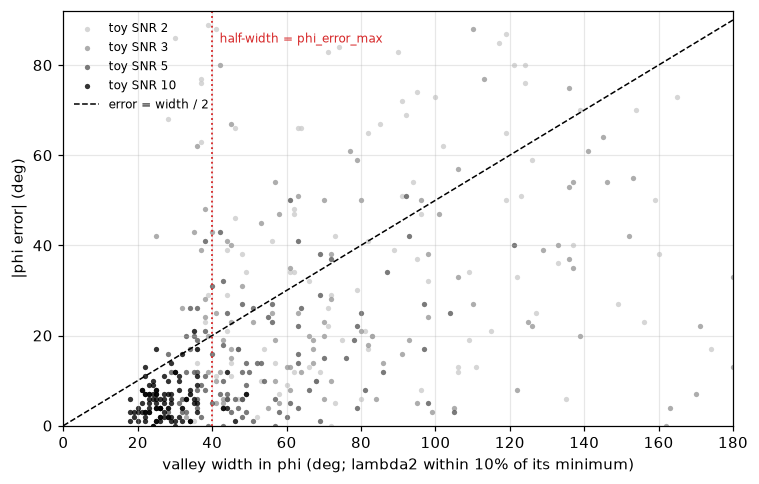

In [22]:
rng = np.random.default_rng(4)
def valley_width(g, tol=0.10):
    """Degrees of phi whose best lambda2 (over all dt) is within tol of the overall minimum."""
    return np.sum(g.min(axis=1) <= g.min() * (1 + tol)) * (phis[1] - phis[0])

rows = []
for snr in (2, 3, 5, 10):
    for k in range(100):
        g = misfit(*add_noise(n1, e1, snr))
        p, d = best(g)
        rows.append({"toy_snr": snr, "phi_err": float(stats.axial_diff(p, PHI_TRUE)), "width": valley_width(g)})
ww = pd.DataFrame(rows)
ww["passes"] = ww.width / 2 <= quality.PostFilter().phi_error_max               # half-width used as the phi_error cut
print(ww.groupby("toy_snr").agg(width_median=("width", "median"), phi_err_median=("phi_err", "median"),
                                pass_gate=("passes", "mean"),
                                wrong_among_passing=("phi_err", lambda x: (x[ww.passes[x.index]] > TOL_DEG).mean())).round(2).to_string())
print(f"\nSpearman rank correlation, width vs error, all {len(ww)} trials: {ww.width.corr(ww.phi_err, method='spearman'):.2f}")
print(f"fraction of trials with error larger than half the width: {(ww.phi_err > ww.width / 2).mean():.2f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
for snr, c in zip((2, 3, 5, 10), ["0.8", "0.6", "0.35", "k"]):
    g_ = ww[ww.toy_snr == snr]
    ax.scatter(g_.width, g_.phi_err, s=12, color=c, alpha=0.8, lw=0, label=f"toy SNR {snr}")
lim = 180
ax.plot([0, lim], [0, lim / 2], "k--", lw=1, label="error = width / 2")
ax.axvline(2 * quality.PostFilter().phi_error_max, color="tab:red", ls=":", lw=1.2)
ax.text(2 * quality.PostFilter().phi_error_max + 2, 85, "half-width = phi_error_max", color="tab:red", fontsize=8)
ax.set(xlabel="valley width in phi (deg; lambda2 within 10% of its minimum)", ylabel="|phi error| (deg)", xlim=(0, lim), ylim=(0, 92))
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()

**Related, but not a guarantee.** On average a wider valley goes with a larger error: the median width shrinks from 74.5 degrees at toy SNR 2 to 26 at SNR 10 while the median error falls from 34 to 5 degrees, and the rank correlation over all 400 trials is 0.55. Most points sit below the error = width / 2 line, so half the width works as a rough error bar.

But 24 percent of trials have an error larger than half their width, and as a gate it fails exactly where it is needed. At toy SNR 2 and 3 only 12 and 13 percent of trials have a half-width under 20 degrees, and 67 and 69 percent of *those* are more than 20 degrees off: the noise made a narrow valley in the wrong place. At SNR 5 the passing trials are wrong 16 percent of the time, at SNR 10 1 percent. A narrow valley says the minimum is well defined, not that it is the right one. That is why a formal error is not enough on its own (notebook 07, section 1), and why the pipeline also asks a second method.

The second method is the cross-correlation search, and Q_w compares the two (Wüstefeld et al., 2010). Below, `xc_grid` is SWSPy's cross-correlation score and `q_w` its formula, on SWSPy's 0.02 s grid. One difference: SWSPy's `_calc_Q_w` takes the plain difference of its two phi values (from Q, between -90 and 90); the synthetic takes the angle between the two axes.

In [23]:
def xc_grid(n, e, win=win, dts=dts):
    """SWSPy's cross-correlation score on the same grid: mean |fast * slow| / (std fast * std slow); maximized."""
    th = np.deg2rad(phis)[:, None]
    fast = (n * np.cos(th) + e * np.sin(th))[:, None, win]
    slow = -n * np.sin(th) + e * np.cos(th)
    S = np.stack([np.roll(slow, -int(round(d * fs)), axis=1)[:, win] for d in dts], axis=1)
    return np.abs(fast * S).mean(-1) / (fast.std(-1) * S.std(-1))

def q_w(phi_ev, dt_ev, phi_xc, dt_xc):
    """Wuestefeld et al. (2010) quality factor, as in SWSPy's _calc_Q_w, with the angle difference taken as the
    angle between the two axes (0 to 90 deg)."""
    rho, dphi = dt_xc / dt_ev, float(stats.axial_diff(phi_ev, phi_xc)) / 45.0
    d_null = min(np.sqrt((rho ** 2 + (dphi - 1) ** 2) / 2), 1.0)
    d_good = min(np.sqrt(((rho - 1) ** 2 + dphi ** 2) / 2), 1.0)
    return -(1 - d_null) if d_null < d_good else 1 - d_good

rng = np.random.default_rng(5)
rows = []
for snr in (5, 10):
    for off in offsets:
        n_, e_ = make_split(src=PHI_TRUE + off)
        for k in range(60):
            nn, ee = add_noise(n_, e_, snr)
            pe, de = best(misfit(nn, ee, dts=dts_swspy, ratio=True), dts=dts_swspy)
            px, dx = best(-xc_grid(nn, ee, dts=dts_swspy), dts=dts_swspy)
            rows.append({"toy_snr": snr, "offset": off, "phi_err": float(stats.axial_diff(pe, PHI_TRUE)),
                         "Q_w": q_w(pe, de, px, dx) if de > 0 else np.nan})
qq = pd.DataFrame(rows)
for cut in (0.5, quality.PostFilter().qw_min):
    qq[f"passes {cut}"] = qq.Q_w >= cut
print("fraction passing each Q_w cut, by angle between source polarization and fast axis (60 trials each):")
print(qq.groupby(["toy_snr", "offset"])[[f"passes 0.5", f"passes {quality.PostFilter().qw_min}"]].mean().unstack(0).round(2).to_string())
for snr in (5, 10):
    q_ = qq[qq.toy_snr == snr]
    for cut in (0.5, quality.PostFilter().qw_min):
        sel = q_[q_.Q_w >= cut]
        print(f"toy SNR {snr}, Q_w >= {cut}: {len(sel)} of {len(q_)} pass; {(sel.phi_err > TOL_DEG).mean():.2f} of them have phi off by more "
              f"than {TOL_DEG:.0f} deg (all trials: {(q_.phi_err > TOL_DEG).mean():.2f})")

fraction passing each Q_w cut, by angle between source polarization and fast axis (60 trials each):
        passes 0.5       passes 0.75      
toy_snr         5     10          5     10
offset                                    
0             0.08  0.00        0.02  0.00
5             0.08  0.00        0.03  0.00
10            0.10  0.05        0.03  0.00
20            0.23  0.40        0.12  0.23
30            0.37  0.98        0.23  0.85
45            0.77  1.00        0.53  0.98
toy SNR 5, Q_w >= 0.5: 98 of 360 pass; 0.18 of them have phi off by more than 20 deg (all trials: 0.40)
toy SNR 5, Q_w >= 0.75: 58 of 360 pass; 0.14 of them have phi off by more than 20 deg (all trials: 0.40)
toy SNR 10, Q_w >= 0.5: 146 of 360 pass; 0.01 of them have phi off by more than 20 deg (all trials: 0.11)
toy SNR 10, Q_w >= 0.75: 124 of 360 pass; 0.00 of them have phi off by more than 20 deg (all trials: 0.11)


**Q_w is a near-null detector more than an accuracy check.** At toy SNR 10 no trial with the source polarization within 10 degrees of the fast axis passes Q_w >= 0.75, which is what it is for. Between 20 and 30 degrees it passes 23 and 85 percent; at 45, 98 percent. Lowering the cut to 0.5 lets through 40 percent at 20 degrees and 98 percent at 30. So **raising the cut from 0.5 to 0.75 mostly removed measurements with source polarizations 20 to 30 degrees from the fast axis**, which at SNR 10 were right: of the passing trials, 1 percent (0.5) and none (0.75) are more than 20 degrees off.

At toy SNR 5 Q_w still separates good from bad, but less cleanly: 40 percent of all trials are more than 20 degrees off, against 18 percent of those passing 0.5 and 14 percent of those passing 0.75, and the stricter cut keeps 58 of 360 trials instead of 98. At STAR:

In [24]:
f50 = quality.post_filtered(res_o, dataclasses.replace(quality.DEFAULT_POST, qw_min=0.5))
removed = f50[~f50.evid.isin(good.evid)]
print(f"STAR: {len(f50)} pass with Q_w >= 0.5, {len(good)} with Q_w >= {quality.PostFilter().qw_min}; raising the cut removed {len(removed)}")
print(f"  removed: Q_w {removed.quality.min():.3f} to {removed.quality.max():.3f}; dt {removed.dt.round(2).value_counts().sort_index().to_dict()}; "
      f"mean phi {stats.axial_mean(removed.phi)[0]:.0f} deg (R = {stats.axial_mean(removed.phi)[1]:.2f}); "
      f"{stats.near_axis(removed.phi, removed.back_azimuth).sum()} of {len(removed)} near their back azimuth")

STAR: 206 pass with Q_w >= 0.5, 194 with Q_w >= 0.75; raising the cut removed 12
  removed: Q_w 0.529 to 0.749; dt {0.02: 7, 0.06: 4, 0.08: 1}; mean phi 56 deg (R = 0.59); 8 of 12 near their back azimuth


At STAR the change was small. 206 events pass the post-processing filter with Q_w >= 0.5 and 194 with 0.75, so raising the cut removed 12, with Q_w between 0.529 and 0.749. They are not like the rest: their fast directions scatter (mean 56 degrees, R = 0.59, against 34 and 0.86), 7 of the 12 have dt 0.02 s, and 8 of the 12 lie within 20 degrees of their back azimuth or its perpendicular. The stricter cut removed a few marginal events from STAR rather than reshaping the result. (The larger change between the archived and corrected STAR results came from the channel fix, not from Q_w; README.)

### Exercise 5: is the anisotropy spread along the whole path?

dt against travel time, N = 194: Spearman -0.01 (p = 0.94)
a uniform 2.9% anisotropy predicts dt to grow by 0.023 s across STAR's travel times (1.36 to 2.16 s); SWSPy's dt step is 0.02 s
S travel time: ray-traced median 1.81 s, catalog (S pick - origin time) median 1.29 s; percent anisotropy with the catalog times: mean 4.12, median 4.50


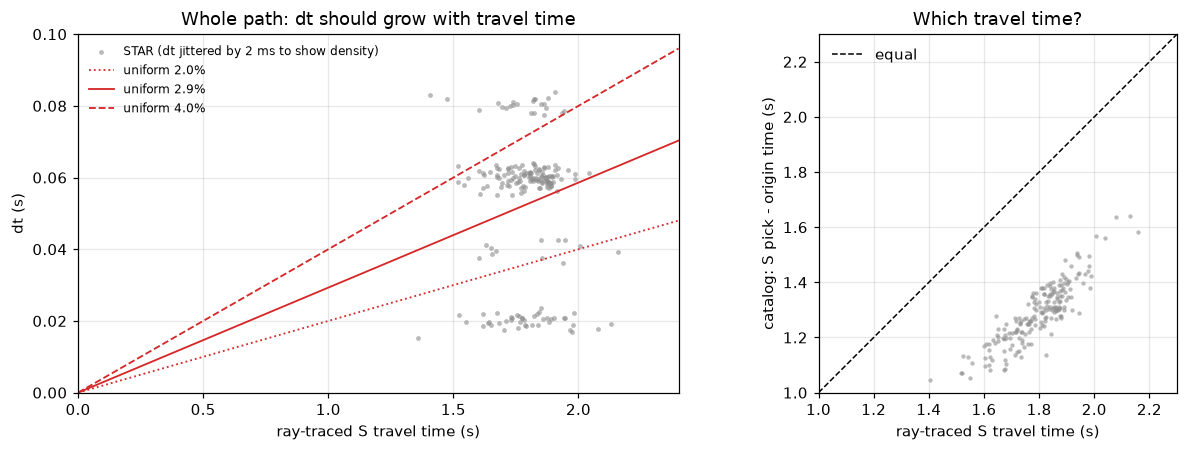

In [25]:
from scipy.stats import spearmanr
rho_s, p_s = spearmanr(good.travel_time_s, good.dt)
print(f"dt against travel time, N = {len(good)}: Spearman {rho_s:.2f} (p = {p_s:.2f})")
spread = m_pct / 100 * (tt.max() - tt.min())
print(f"a uniform {m_pct:.1f}% anisotropy predicts dt to grow by {spread:.3f} s across STAR's travel times "
      f"({tt.min():.2f} to {tt.max():.2f} s); SWSPy's dt step is {step:.2f} s")
obs = good.merge(cat[["evid", "origin_time", "s_time"]], on="evid")
obs_tt = (obs.s_time - obs.origin_time).dt.total_seconds()
print(f"S travel time: ray-traced median {tt.median():.2f} s, catalog (S pick - origin time) median {obs_tt.median():.2f} s; "
      f"percent anisotropy with the catalog times: mean {(100 * obs.dt / obs_tt).mean():.2f}, median {(100 * obs.dt / obs_tt).median():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
jit = np.random.default_rng(0).normal(0, 0.002, len(good))
axes[0].scatter(tt, good.dt + jit, s=10, color="0.55", alpha=0.6, lw=0, label="STAR (dt jittered by 2 ms to show density)")
tt_line = np.linspace(0, 2.4, 2)
for pc, ls in [(2, ":"), (m_pct, "-"), (4, "--")]:
    axes[0].plot(tt_line, pc / 100 * tt_line, color="tab:red", ls=ls, lw=1.2, label=f"uniform {pc:.1f}%")
axes[0].set(xlim=(0, 2.4), ylim=(0, 0.1), xlabel="ray-traced S travel time (s)", ylabel="dt (s)",
            title="Whole path: dt should grow with travel time")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
axes[1].scatter(tt, obs_tt.to_numpy(), s=8, color="0.55", alpha=0.6, lw=0)
axes[1].plot([1, 2.3], [1, 2.3], "k--", lw=1, label="equal")
axes[1].set(xlabel="ray-traced S travel time (s)", ylabel="catalog: S pick - origin time (s)", xlim=(1, 2.3), ylim=(1, 2.3),
            aspect="equal", title="Which travel time?")
axes[1].legend(frameon=False, loc="upper left")
plt.tight_layout()

**STAR cannot tell.** dt does not grow with travel time (Spearman -0.01, p = 0.94, N = 194), but that is not evidence for a thin layer: a uniform anisotropy of 2.9 percent predicts dt to grow by only 0.023 s from the shortest travel time to the longest (1.36 to 2.16 s), about one step of SWSPy's 0.02 s grid. Within STAR's range the expected trend is the size of the quantization. To separate "the whole path" from "near the station" you need a range of path lengths several times wider, with the anisotropy measured the same way: several stations at different distances inside the shear-wave window, which is the week-8 benchmark and the nodes (section 7).

**Which travel time is a real question.** The ray-traced travel time (median 1.81 s) is about 40 percent longer than the catalog's S pick minus origin time (median 1.29 s), for every event (right panel). Dividing by the catalog time gives a percent anisotropy of 4.12 on average (median 4.50) instead of 2.93 (3.25). The catalog's origin time is fitted by PNSN's location with its own velocity model, and the ray tracer uses another, so neither is model-free; but a 40 percent difference in the denominator is larger than any change in anisotropy the project hopes to detect between swarms. For comparisons between stations or times, use one definition consistently and say which; for absolute values, the velocity model is part of the error bar.